# Lab 2 : OD Matrices analytics

## Setup of datasets and visualization

In [1]:
%pip install geopandas "folium>=0.12" matplotlib mapclassify pymongo

Note: you may need to restart the kernel to use updated packages.


In [2]:
!pip install "folium>=0.12" matplotlib mapclassify

In [3]:
import pymongo as pm
from pprint import pprint
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime, timezone
import geopandas as gpd
from shapely.geometry import box
from geopandas import GeoDataFrame
from shapely.geometry import box
from branca.colormap import linear
from IPython.display import display
import seaborn as sns
import ipywidgets as widgets
from itertools import combinations
import json, os
from matplotlib.path import Path
from matplotlib.colors import LogNorm
from scipy.spatial.distance import jensenshannon

os.makedirs('out', exist_ok=True)

In [4]:
client = pm.MongoClient(
 'bigdatadb.polito.it',
 ssl=True,
 authSource='carsharing',
 username='ictts',
 password='Ict4SM22!',
 tlsAllowInvalidCertificates=True
)

In [5]:
db= client['carsharing']
pb_coll = db['ictts_PermanentBookings']
pb_coll_enjoy= db['ictts_enjoy_PermanentBookings']

In [6]:
def load_wtime(db, coll, carsharing=True):
    if carsharing:
        pipe = [
            {
                "$match": {
                    "driving.duration": {"$gt": 0},
                    "driving.distance": {"$gt": 0}
                }
            },
            {
                "$project": {
                    "_id": 0,
                    "init_time": 1,
                    "final_time": 1,
                    "duration": "$driving.duration",
                    "day": {
                        "$dateToString": {
                            "date": "$init_date",
                            "format": "%Y-%m-%d"
                        }
                    },
                    "week": {"$isoWeek": "$init_date"},
                    "iso_year": {"$isoWeekYear": "$init_date"},
                    "dow": {"$isoDayOfWeek": "$init_date"},
                    "hour": {"$hour": "$init_date"},
                    "vendor": 1,
                    "init_address": 1,
                    "final_address": 1,
                    "plate": 1,
                    "init_loc": 1,
                    "final_loc": 1,
                    "driving": 1,
                    "walking": 1,
                    'init_date':1
                }
            }
        ]

    else:
        raise NotImplementedError(
            "Non-carsharing data processing is not implemented yet."
        )

    collection = db[coll] if isinstance(coll, str) else coll
    df = pd.DataFrame(collection.aggregate(pipe, allowDiskUse=True))

    if df.empty:
        print("Warning: MongoDB query returned no documents.")
        return df

    df["duration_min"] = df["duration"] / 60

    df["driving_distance_km"] = df["driving"].apply(
        lambda x: x["distance"] / 1000
        if isinstance(x, dict) else np.nan
    )

    df["walking_duration_min"] = df["walking"].apply(
        lambda x: x["duration"] / 60
        if isinstance(x, dict) else np.nan
    )

    return df

## Question 1

For this question we started to look at the data to see if we needed to adapt our filtering from the first lab.

In [7]:
def load_raw(coll, city="Torino"):
    pipe = [
        {
            "$match": {
                "city": city,
               }
        },
        {"$project": {
            "_id": 0,
            "plate": 1,
            "init_date": 1, "final_date": 1,
            "init_time": 1, "final_time": 1,
            "init_loc": 1, "final_loc": 1,
            "drv_dur": "$driving.duration",
            "drv_dist": "$driving.distance",
        }},
    ]
    df = pd.DataFrame(coll.aggregate(pipe, allowDiskUse=True))
    df["rental_min"] = (df["final_time"] - df["init_time"]) / 60
    df["drv_dist_km"] = df["drv_dist"] / 1000
    df["init_date"] = pd.to_datetime(df["init_date"])
    # coordinates to test "start == end"
    df["same_loc"] = df["init_loc"].apply(lambda x: tuple(x["coordinates"])) == \
                     df["final_loc"].apply(lambda x: tuple(x["coordinates"]))
    return df.drop(columns=["init_loc", "final_loc"])

raw = {
    "Car2Go": load_raw(pb_coll),
    "Enjoy":  load_raw(pb_coll_enjoy),
}

def explore(df, name):
    print(f"--- {name} ---")
    print("duration < 1 min      :", (df.rental_min < 1).sum())
    print("duration > 3 h        :", (df.rental_min > 180).sum())
    print("duration > 24 h       :", (df.rental_min > 1440).sum())
    print("distance <= 0         :", (df.drv_dist <= 0).sum())
    print("start == end          :", df.same_loc.sum())
    print(df[["rental_min", "drv_dist_km"]].describe(percentiles=[.01, .05, .5, .95, .99]))

for name, df in raw.items():
    explore(df, name)

--- Car2Go ---
duration < 1 min      : 0
duration > 3 h        : 0
duration > 24 h       : 0
distance <= 0         : 82477
start == end          : 0
          rental_min    drv_dist_km
count  121667.000000  121667.000000
mean       20.889914       1.251278
std         9.849642       2.200316
min         2.100000      -0.001000
1%          4.750000      -0.001000
5%          7.633333      -0.001000
50%        19.433333      -0.001000
95%        39.650000       5.789000
99%        51.750000       8.347680
max        59.983333      33.401000
--- Enjoy ---
duration < 1 min      : 0
duration > 3 h        : 0
duration > 24 h       : 0
distance <= 0         : 61447
start == end          : 0
         rental_min   drv_dist_km
count  97173.000000  97173.000000
mean      23.405766      1.494120
std       10.423864      2.434082
min        3.066667     -0.001000
1%         7.616667     -0.001000
5%         8.466667     -0.001000
50%       20.533333     -0.001000
95%       44.316667      6.278000
9

We can see that there is a lot of duration below 0 so we just filter it in the pipe.\
The only filter needed is a distance one. It cut 67.79% data for the car2go database and 63.23% for the enjoy Database.

For the rest of the question we only used the filtering on the distance and the duration that must be >0.

### Loading the trips
`load_wtime` (MongoDB) returns the filtered rentals. The origin and destination are stored as GeoJSON points (`{'type': 'Point', 'coordinates': [lon, lat]}`),
so we extract longitude and latitude in four separate columns: they are needed to find the zone of each point.

In [8]:
#we add the columns for the coordinates
bookings = {'car2go': load_wtime(db, pb_coll), 'enjoy': load_wtime(db, pb_coll_enjoy)}
for name, df in bookings.items():
    
    df['orig_lon'] = df['init_loc'].apply(lambda p: p['coordinates'][0])
    df['orig_lat'] = df['init_loc'].apply(lambda p: p['coordinates'][1])
    df['dest_lon'] = df['final_loc'].apply(lambda p: p['coordinates'][0])
    df['dest_lat'] = df['final_loc'].apply(lambda p: p['coordinates'][1])
    
    print(f'{name}: {len(df)} rentals kept')

car2go: 39190 rentals kept
enjoy: 35726 rentals kept


### Functions – zones of Torino
- `TorinoZonescol.geojson` contains only the 23 polygons, without zone codes. `FILE_ORDER` gives the IMQ code (Q001–Q023) of each polygon following the order of the file (checked against another zone file of the IMQ data); the names come from `tab_zone_IMQ.csv`.
- `point_zone` is a point-in-polygon test (`matplotlib.path.Path.contains_points`) done for all points at once, zone by zone; holes in the polygons are excluded.
- `assign_zones` adds the origin (`orig`) and destination (`dest`) zone of each trip and drops the trips starting or ending outside Torino

In [9]:
# order of the features in TorinoZonescol.geojson (checked against the IMQ zone list)
FILE_ORDER = [f'Q{i:03d}' for i in range(1, 20)] + ['Q021', 'Q022', 'Q020', 'Q023']

def load_zones(path, names_path='data/IMQ/IMQData/tab_zone_IMQ.csv'):
    """23 zones of Torino: {code: geometry}, sorted list of codes, {code: name}."""
    with open(path) as f:
        fc = json.load(f)
    zones = {code: feature['geometry'] for code, feature in zip(FILE_ORDER, fc['features'])}
    table = pd.read_csv(names_path, encoding='latin-1', dtype=str).set_index('COD_ZONA')['nome_zona']
    names = {code: table[code].replace('TORINO - ', '').title() for code in zones}
    return zones, sorted(zones), names


def point_zone(lon, lat, zones):
    """Zone code of each point (lon, lat); None if outside all zones."""
    pts = np.column_stack([np.asarray(lon, float), np.asarray(lat, float)])
    out = np.full(len(pts), None, dtype=object)
    for code in sorted(zones):
        geom = zones[code]
        polys = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
        inside = np.zeros(len(pts), dtype=bool)
        for poly in polys:
            m = Path(poly[0]).contains_points(pts)
            for hole in poly[1:]:
                m &= ~Path(hole).contains_points(pts)
            inside |= m
        out[inside & pd.isna(out)] = code
    return out


def assign_zones(df, zones):
    """Adds orig/dest zone codes and keeps only trips starting and ending inside the zones."""
    df = df.copy()
    df['orig'] = point_zone(df.orig_lon, df.orig_lat, zones)
    df['dest'] = point_zone(df.dest_lon, df.dest_lat, zones)
    inside = df.dropna(subset=['orig', 'dest'])
    print(f'{len(inside)}/{len(df)} trips inside the Torino zones ({len(inside) / len(df):.1%})')
    return inside

### Functions – periods
- `add_time_columns` adds date, hour, day of week (0 = Monday) and calendar (ISO) week, so that the same week numbers can be used in the report.
- `select_period` keeps only the trips of a period: weekdays/weekend, an hour window (it also works over midnight, e.g. 22→6 for the night) and/or a list of weeks.
  One function for all the periods keeps the comparisons of Q1a, Q1b and Q1c consistent.

In [10]:
def add_time_columns(df):
    """Date, hour, day of week (0 = Monday) and calendar (ISO) week of each trip."""
    df = df.copy()
    d = pd.to_datetime(df['init_date'])
    df['date'] = d.dt.strftime('%Y-%m-%d')
    df['hour'] = d.dt.hour
    df['dow'] = d.dt.dayofweek
    df['week'] = d.dt.isocalendar().week.astype(int)
    return df


def select_period(df, days='all', hours=None, weeks=None):
    """days: 'all', 'weekdays' or 'weekend'; hours: (start, end), e.g. (22, 6) goes over midnight;
    weeks: list of calendar weeks."""
    mask = pd.Series(True, index=df.index)
    if days == 'weekdays':
        mask &= df.dow < 5
    elif days == 'weekend':
        mask &= df.dow >= 5
    if hours is not None:
        start, end = hours
        if start <= end:
            mask &= (df.hour >= start) & (df.hour < end)
        else:
            mask &= (df.hour >= start) | (df.hour < end)
    if weeks is not None:
        mask &= df.week.isin(weeks)
    return df[mask]

### Functions – OD matrix and comparison
- `od_matrix` counts the trips for each origin–destination pair with a pivot table, then `reindex` gives always the same 23×23 shape (pairs without trips = 0, so every matrix can be compared with every other).
  The matrix is normalized to sum 1: each cell is the fraction of trips from zone i to zone j, so periods with a different number of trips can be compared.
- `tvd` (total variation distance) = ½ Σ|A − B|, in %: 0 = identical, 100 = no common OD pair. It is half the L1 distance of Q2, but easier to read as a percentage.
- `top_changes` lists the OD pairs whose share changes the most: the TVD says how much two matrices differ, `top_changes` says where.

In [11]:
def od_matrix(df, zones_list, norm=True):
    """23 x 23 OD matrix (pivot table of trip counts); pairs without trips = 0; normalized to sum 1."""
    m = pd.pivot_table(df, index='orig', columns='dest', values='duration_min',
                       aggfunc='count', fill_value=0)
    m = m.reindex(index=zones_list, columns=zones_list, fill_value=0)
    m.index.name, m.columns.name = 'orig', 'dest'
    return m / m.values.sum() if norm else m


def tvd(A, B):
    """Total variation distance in %: 0 = identical, 100 = completely different."""
    return 0.5 * np.abs(A.values - B.values).sum() * 100


def top_changes(A, B, label_a='A', label_b='B', n=10):
    """The n OD pairs whose share of trips changes the most between A and B (percentage points)."""
    D = (A - B).stack()
    idx = D.abs().sort_values(ascending=False).index[:n]
    return pd.DataFrame({
        'origin': [f'{o} {ZONE_NAMES[o]}' for o, _ in idx],
        'destination': [f'{d} {ZONE_NAMES[d]}' for _, d in idx],
        f'{label_a} (%)': [A.loc[o, d] * 100 for o, d in idx],
        f'{label_b} (%)': [B.loc[o, d] * 100 for o, d in idx],
        'difference (p.p.)': [D[(o, d)] * 100 for o, d in idx],
    }).round(2)

### Functions – heatmaps
`plot_heatmaps` draws several OD matrices side by side with the same log colour scale (most pairs have very few trips, a linear scale would show only the Centro).
log(0) does not exist, so pairs without trips are masked and drawn in grey; this only affects the plot, the matrices keep the zeros.

In [12]:
from matplotlib.colors import LogNorm

def zone_labels(codes):
    return [f'{c} {ZONE_NAMES.get(c, "")}' for c in codes]


def plot_heatmaps(mats, title='', fname=None):
    """mats = {label: OD matrix}, side by side, same log colour scale; cells with no trips in grey."""
    vals = np.concatenate([m.values.ravel() for m in mats.values()])
    pos = vals[vals > 0]
    norm = LogNorm(vmin=np.percentile(pos, 1), vmax=pos.max())
    cmap = plt.get_cmap('viridis').copy()
    cmap.set_bad('#dddddd')
    fig, axes = plt.subplots(1, len(mats), figsize=(7.5 * len(mats), 7), squeeze=False, constrained_layout=True)
    for ax, (name, m) in zip(axes[0], mats.items()):
        im = ax.imshow(np.ma.masked_where(m.values <= 0, m.values), cmap=cmap, norm=norm)
        ax.set_title(name, fontsize=12)
        ax.set_xticks(range(len(m.columns))); ax.set_xticklabels(zone_labels(m.columns), rotation=90, fontsize=7)
        ax.set_yticks(range(len(m.index))); ax.set_yticklabels(zone_labels(m.index), fontsize=7)
        ax.set_xlabel('destination zone'); ax.set_ylabel('origin zone')
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.7, label='fraction of trips (log scale)')
    fig.suptitle(title, fontsize=14)
    if fname: fig.savefig(f'out/{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()


### Functions – maps of Torino
`plot_zone_maps` colours each zone on the map of Torino. We use it for the share of trips startin in each zone (sum of each row of the OD matrix, pO) or ending there (pD).
With `diverging=True` it draws a difference: red = positive, blue = negative, white = no change. `lim` fixes the colour scale, so that different difference maps can be compared (same red = same difference).
The maps are easier to read than the difference heatmaps, but they show only departures, not the pairs: for the pairs we use `top_changes`.

In [13]:
def plot_zone_maps(values, title='', fname=None, label='', lim=None, diverging=False):
    """values = {panel title: Series indexed by zone code}: each zone coloured by its value, same scale.
       diverging=True: red = positive, blue = negative, white = 0 (for differences)
    """
    if diverging:
        lim = lim or max(v.abs().max() for v in values.values()) 
        norm, cmap = plt.Normalize(-lim, lim), plt.get_cmap('RdBu_r')
    else:
        norm, cmap = plt.Normalize(0, max(v.max() for v in values.values())), plt.get_cmap('YlOrRd')
    fig, axes = plt.subplots(1, len(values), figsize=(4.5 * len(values), 5), squeeze=False, constrained_layout=True)
    for ax, (name, v) in zip(axes[0], values.items()):
        for code, geom in zones.items():
            polys = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
            for poly in polys:
                ring = np.array(poly[0])
                ax.fill(ring[:, 0], ring[:, 1], color=cmap(norm(v.get(code, 0))), edgecolor='black', linewidth=0.5)
        ax.set_aspect(1 / np.cos(np.radians(45.07)))
        ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes[0].tolist(), shrink=0.7, label=label)
    fig.suptitle(title)
    if fname: fig.savefig(f'out/{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()

### OD matrices on the 23 zones (all trips)

In [15]:
os.chdir('/home/students/s359718')

38941/39190 trips inside the Torino zones (99.4%)
35541/35726 trips inside the Torino zones (99.5%)


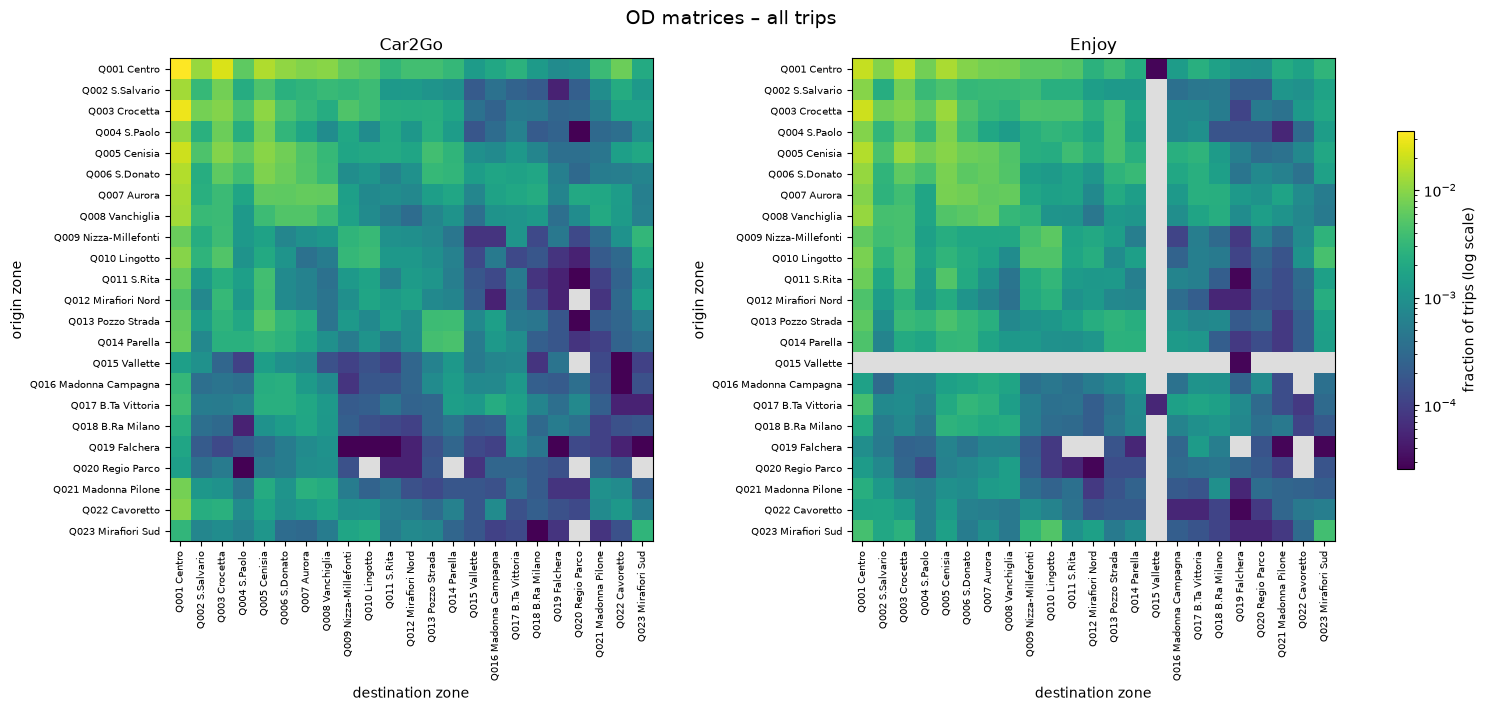

In [16]:
zones, ZONES, ZONE_NAMES = load_zones('data/IMQ/Zone/TorinoZonescol.geojson')
trips = {name: add_time_columns(assign_zones(df, zones)) for name, df in bookings.items()}

od_all = {name: od_matrix(df, ZONES) for name, df in trips.items()}
plot_heatmaps({'Car2Go': od_all['car2go'], 'Enjoy': od_all['enjoy']}, 'OD matrices – all trips', 'task1_od')

### Q1a – Different periods
Weekdays vs weekends, daytime (6–22h) vs night-time, for each platform.

In [17]:
DAY_HOURS = (6, 22)
PERIODS = {
    'Weekdays':   dict(days='weekdays'),
    'Weekends':   dict(days='weekend'),
    'Daytime':    dict(hours=DAY_HOURS),
    'Night-time': dict(hours=DAY_HOURS[::-1]),
}

od_periods = {}
for vendor, df in trips.items():
    od_periods[vendor] = {}
    for name, kw in PERIODS.items():
        sel = select_period(df, **kw)
        od_periods[vendor][name] = od_matrix(sel, ZONES)
        print(f'{vendor:7s} {name:11s}: {len(sel):6d} trips')

car2go  Weekdays   :  29027 trips
car2go  Weekends   :   9914 trips
car2go  Daytime    :  28240 trips
car2go  Night-time :  10701 trips
enjoy   Weekdays   :  26549 trips
enjoy   Weekends   :   8992 trips
enjoy   Daytime    :  23929 trips
enjoy   Night-time :  11612 trips


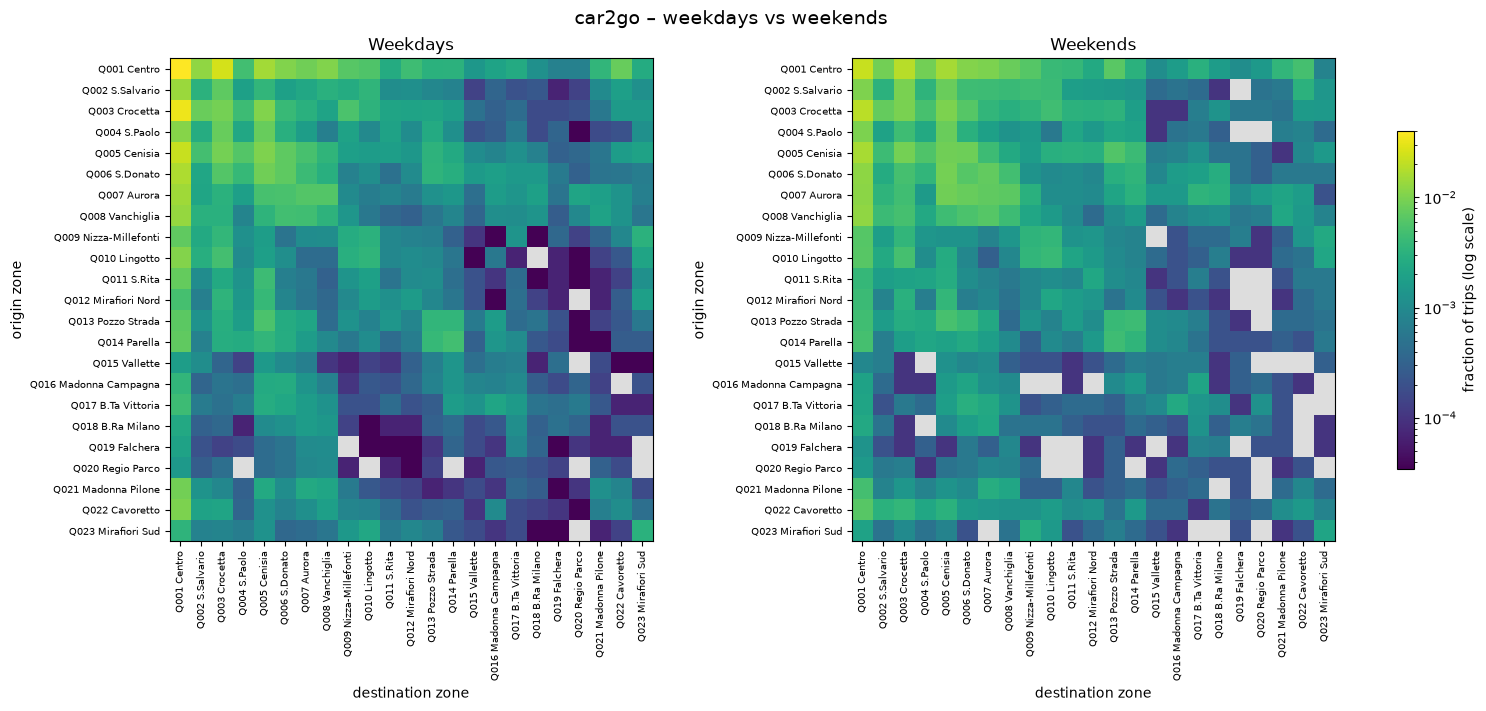

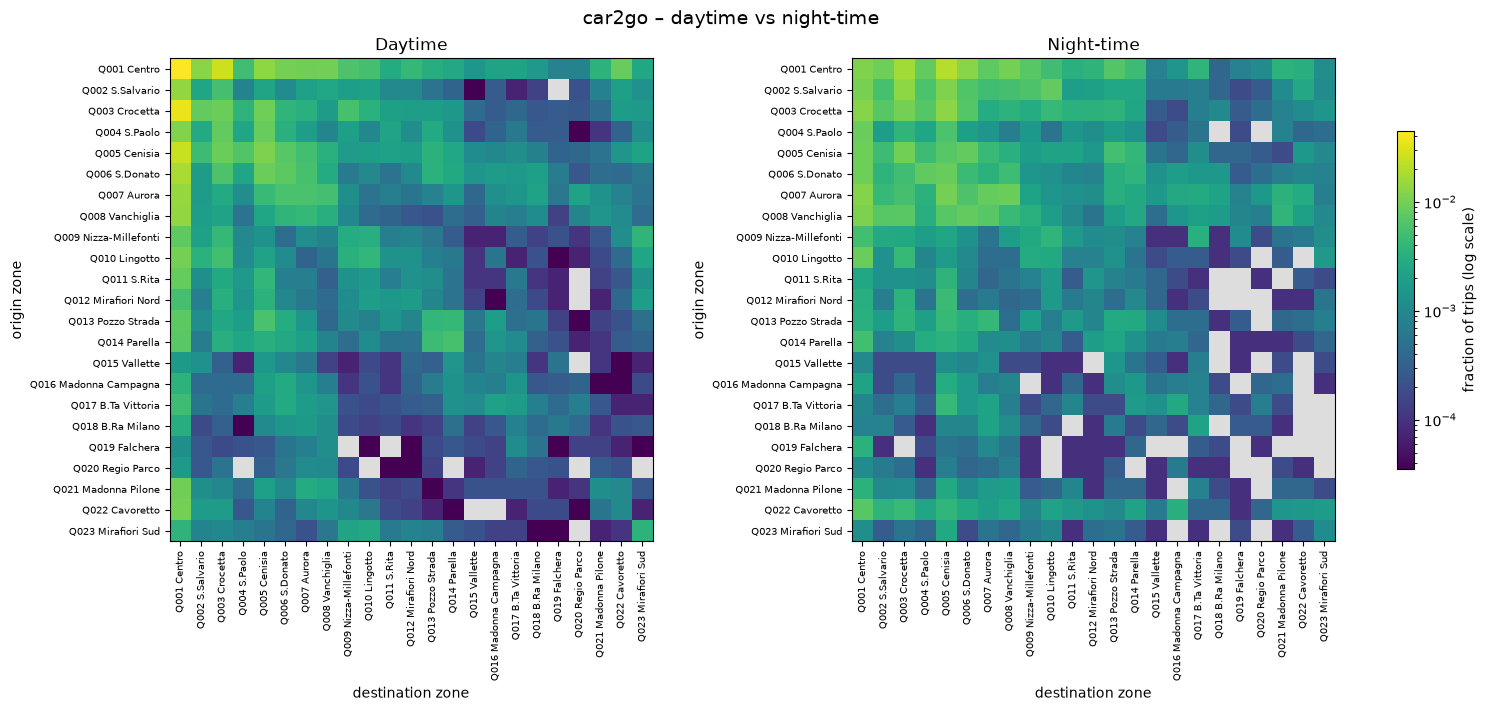

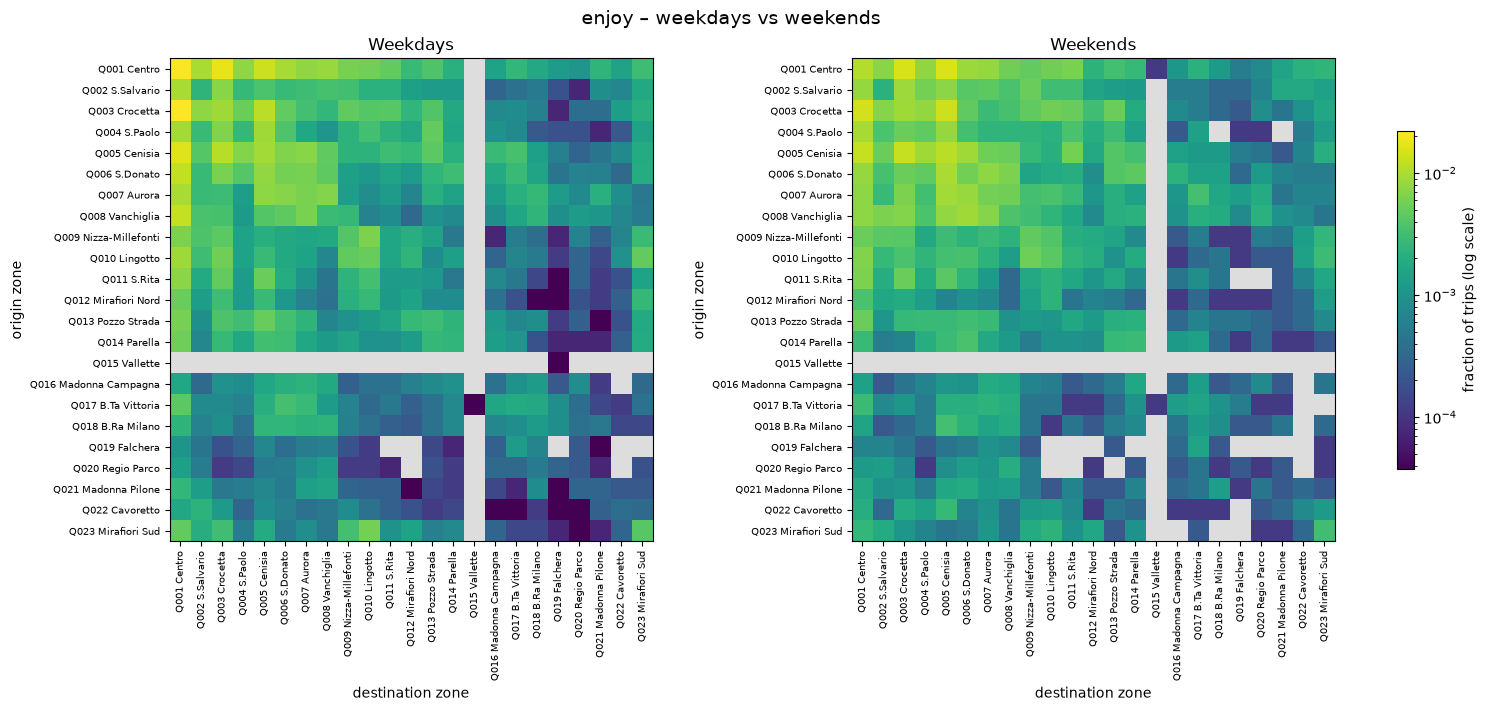

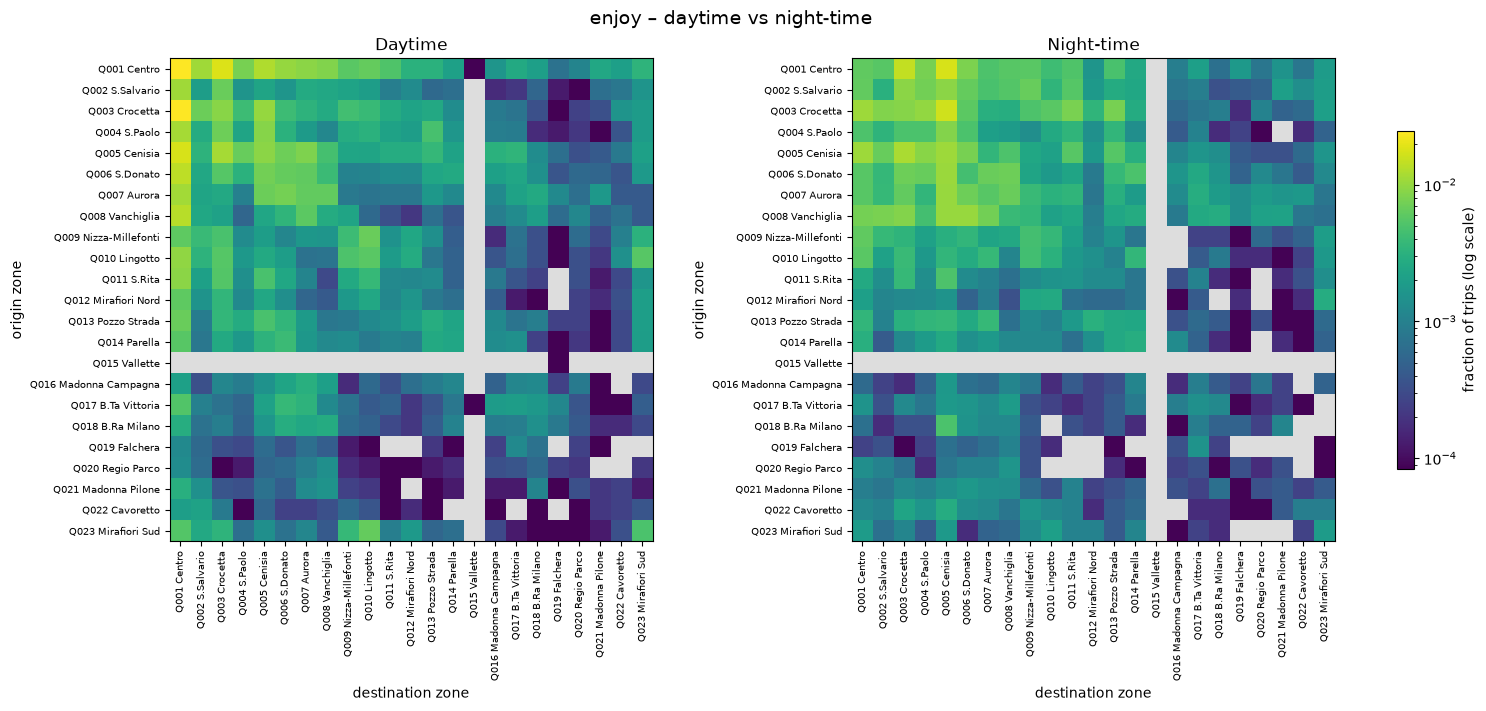

In [18]:
# heatmaps of each period and differences (red = more in the first period, blue = more in the second)
for vendor, P in od_periods.items():
    plot_heatmaps({'Weekdays': P['Weekdays'], 'Weekends': P['Weekends']},
                  f'{vendor} – weekdays vs weekends', f'task1a_{vendor}_week')
    plot_heatmaps({'Daytime': P['Daytime'], 'Night-time': P['Night-time']},
                  f'{vendor} – daytime vs night-time', f'task1a_{vendor}_day')

In [19]:
# how different (TVD) and where (OD pairs that change the most)
for vendor, P in od_periods.items():
    print(f"{vendor}: TVD weekdays vs weekends = {tvd(P['Weekdays'], P['Weekends']):.1f}%, "
          f"daytime vs night-time = {tvd(P['Daytime'], P['Night-time']):.1f}%")
    display(top_changes(P['Weekdays'], P['Weekends'], 'Weekdays', 'Weekends', n=5))
    display(top_changes(P['Daytime'], P['Night-time'], 'Daytime', 'Night-time', n=5))

car2go: TVD weekdays vs weekends = 16.9%, daytime vs night-time = 27.4%


,origin,destination,Weekdays (%),Weekends (%),difference (p.p.)
0,Q001 Centro,Q001 Centro,4.01,2.22,1.79
1,Q003 Crocetta,Q001 Centro,3.32,1.95,1.37
2,Q001 Centro,Q003 Crocetta,2.53,1.88,0.65
3,Q005 Cenisia,Q001 Centro,2.20,1.58,0.62
4,Q006 S.Donato,Q001 Centro,1.69,1.20,0.49


,origin,destination,Daytime (%),Night-time (%),difference (p.p.)
0,Q001 Centro,Q001 Centro,4.48,1.11,3.37
1,Q003 Crocetta,Q001 Centro,3.63,1.23,2.40
2,Q005 Cenisia,Q001 Centro,2.46,0.93,1.53
3,Q001 Centro,Q003 Crocetta,2.63,1.65,0.98
4,Q006 S.Donato,Q001 Centro,1.81,0.92,0.89


enjoy: TVD weekdays vs weekends = 16.2%, daytime vs night-time = 26.5%


,origin,destination,Weekdays (%),Weekends (%),difference (p.p.)
0,Q001 Centro,Q001 Centro,2.14,1.07,1.07
1,Q003 Crocetta,Q001 Centro,2.22,1.43,0.78
2,Q008 Vanchiglia,Q001 Centro,1.28,0.75,0.53
3,Q008 Vanchiglia,Q006 S.Donato,0.45,0.90,-0.45
4,Q006 S.Donato,Q001 Centro,1.24,0.80,0.43


,origin,destination,Daytime (%),Night-time (%),difference (p.p.)
0,Q001 Centro,Q001 Centro,2.47,0.62,1.85
1,Q003 Crocetta,Q001 Centro,2.47,1.09,1.39
2,Q006 S.Donato,Q001 Centro,1.40,0.56,0.84
3,Q008 Vanchiglia,Q005 Cenisia,0.24,1.03,-0.79
4,Q005 Cenisia,Q001 Centro,1.77,1.07,0.70


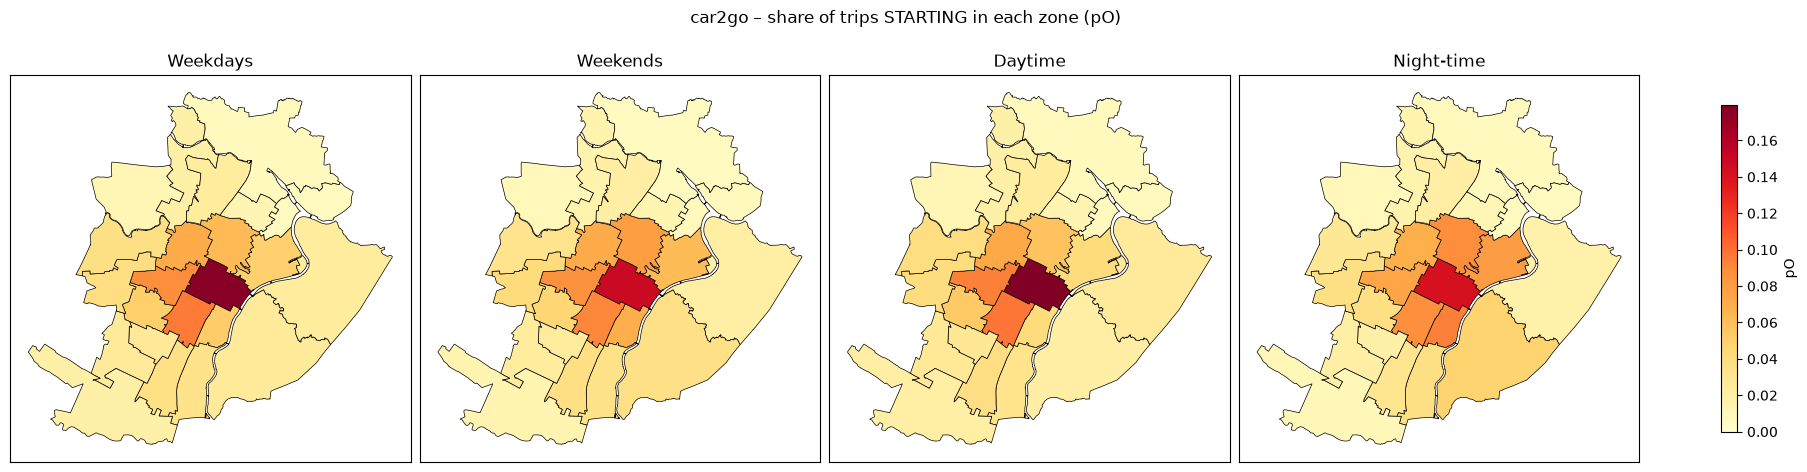

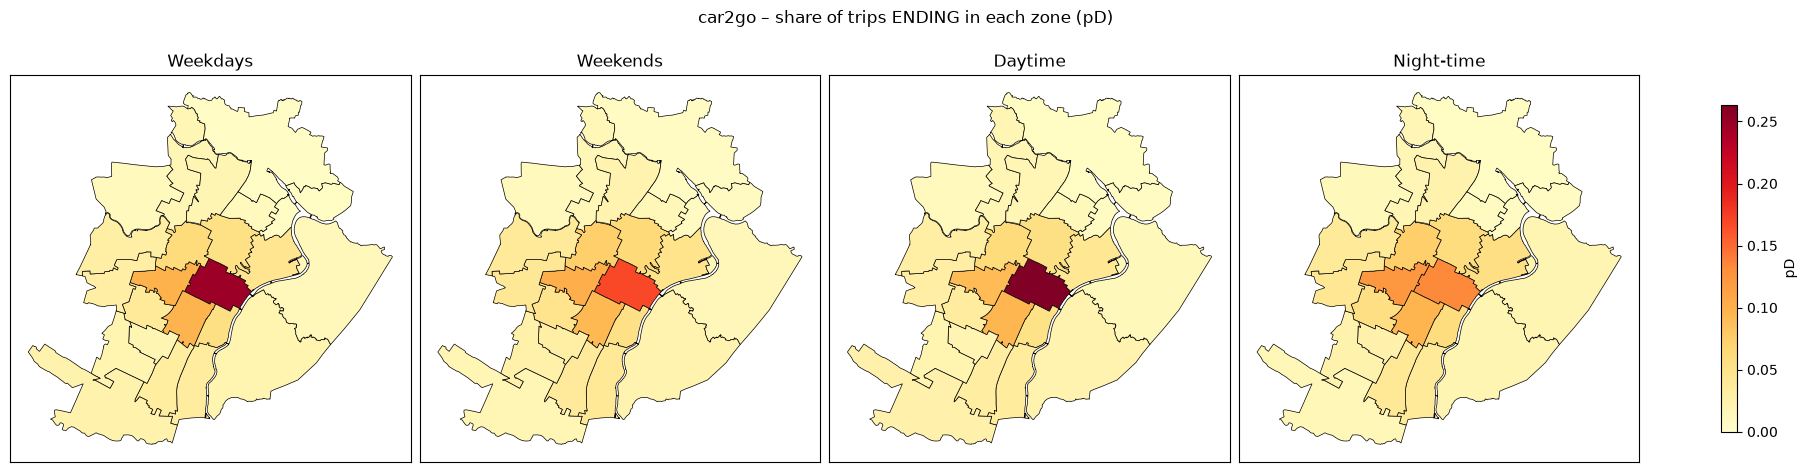

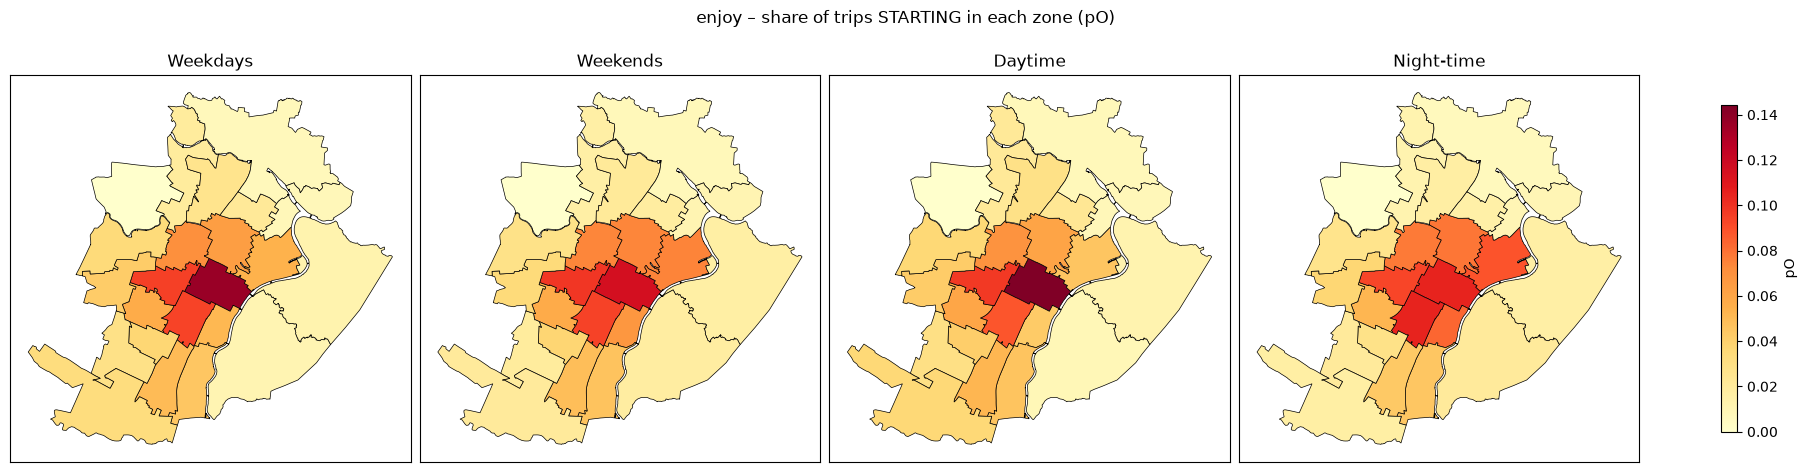

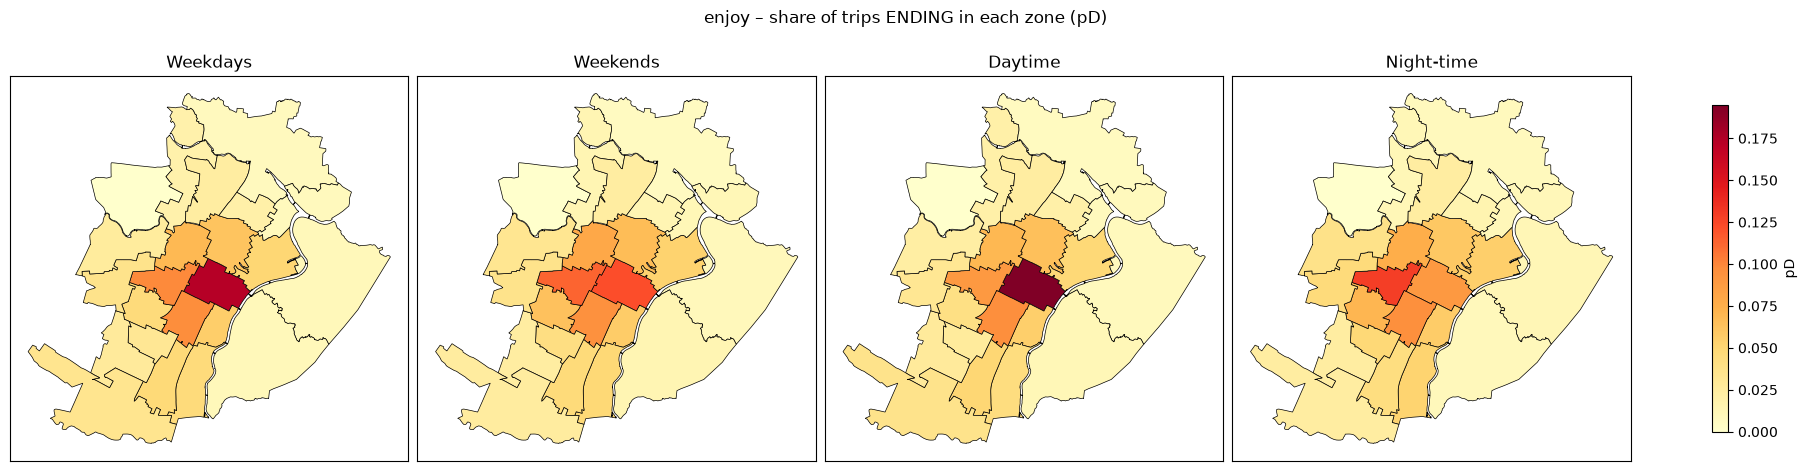

In [20]:
# share of trips starting (pO) and ending (pD) in each zone, for each period
for vendor, P in od_periods.items():
    plot_zone_maps({name: m.sum(axis=1) for name, m in P.items()},
                   f'{vendor} – share of trips STARTING in each zone (pO)', f'task1a_{vendor}_pO', 'pO')
    plot_zone_maps({name: m.sum(axis=0) for name, m in P.items()},
                   f'{vendor} – share of trips ENDING in each zone (pD)', f'task1a_{vendor}_pD', 'pD')

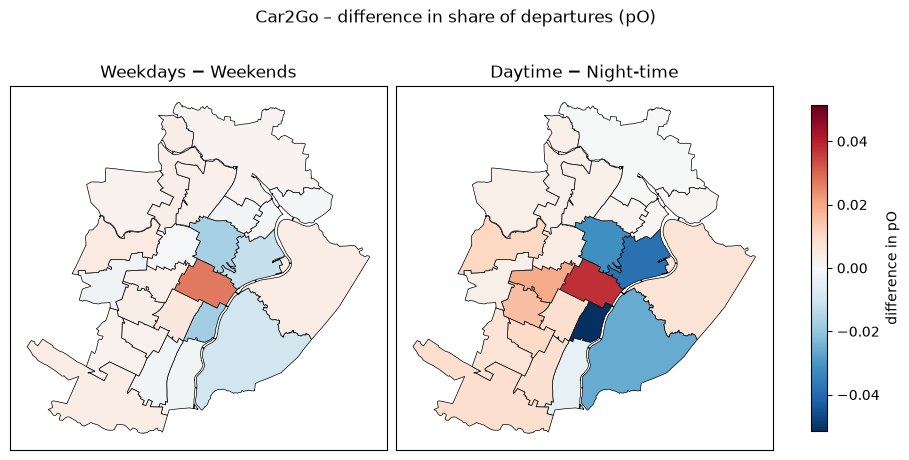

In [21]:
# Q1a: where the share of departures changes between periods (Car2Go)
P = {name: m.sum(axis=1) for name, m in od_periods['car2go'].items()}
plot_zone_maps({'Weekdays − Weekends': P['Weekdays'] - P['Weekends'],
                'Daytime − Night-time': P['Daytime'] - P['Night-time']},
               'Car2Go – difference in share of departures (pO)', 'task1a_car2go_map_diff', 'difference in pO', diverging=True)

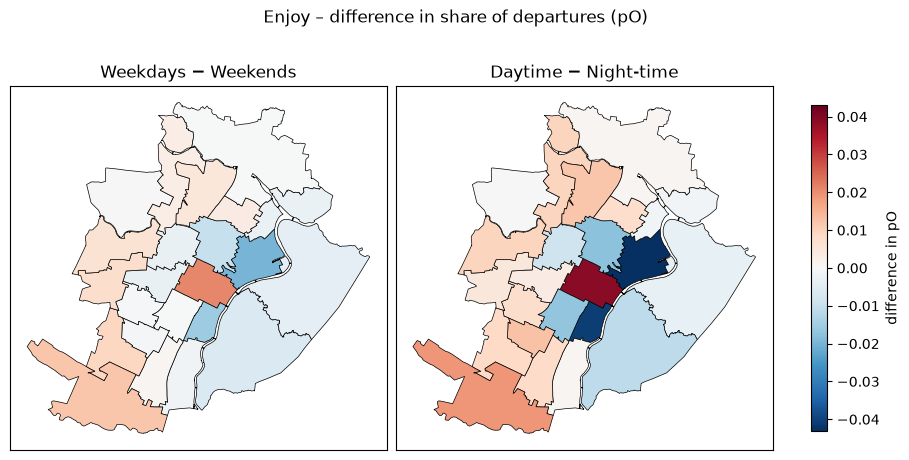

In [22]:
# Q1a: where the share of departures changes between periods (Car2Go)
P = {name: m.sum(axis=1) for name, m in od_periods['enjoy'].items()}
plot_zone_maps({'Weekdays − Weekends': P['Weekdays'] - P['Weekends'],
                'Daytime − Night-time': P['Daytime'] - P['Night-time']},
               'Enjoy – difference in share of departures (pO)', 'task1a_enjoy_map_diff', 'difference in pO', diverging=True)

### Q1b – Same period, different dates
We compare the weekday OD matrices of different calendar weeks (main example: weeks 41 and 43).
The share of rentals without a route changes from day to day, so some days keep very few trips: `full_weeks` uses only the weeks in which every weekday has at least 50% of the median daily number of trips.

To know whether a difference between two weeks is real or only due to the limited number of trips, we use a noise reference: the same week split into two random halves.
If two different weeks differ less than two random halves of the same week, the week-to-week difference is compatible with randomness.

In [23]:
for vendor, df in trips.items():
    wd = select_period(df, days='weekdays')
    print(vendor, '- weekday trips per calendar week (rows) and day (0 = Monday)')
    display(pd.crosstab(wd.week, wd.dow))

car2go - weekday trips per calendar week (rows) and day (0 = Monday)


dow,0,1,2,3,4
week,,,,,
35,0,0,0,0,861
36,0,906,559,481,816
37,805,764,891,438,790
38,528,655,656,718,758
39,177,234,547,827,853
40,806,614,879,434,753
41,803,896,596,798,542
42,843,795,470,726,930
43,853,659,453,755,764


enjoy - weekday trips per calendar week (rows) and day (0 = Monday)


dow,0,1,2,3,4
week,,,,,
35,0,0,0,0,740
36,0,304,513,843,411
37,668,718,633,746,637
38,669,667,671,698,157
39,738,774,729,697,687
40,676,731,106,755,612
41,579,648,654,710,607
42,645,745,699,768,164
43,654,739,606,680,667


In [24]:
def full_weeks(df, min_share=0.5):
    """Weeks where every weekday has at least min_share of the typical (median) daily number of trips."""
    wd = select_period(df, days='weekdays')
    per_day = pd.crosstab(wd.week, wd.dow)
    typical = np.median(per_day.values[per_day.values > 0])
    return list(per_day.index[(per_day >= min_share * typical).all(axis=1)])

FULL_WEEKS = {vendor: full_weeks(df) for vendor, df in trips.items()}
print(FULL_WEEKS)
WEEK_A, WEEK_B = 41, 43     # must be in both lists above

{'car2go': [37, 38, 40, 41, 42, 43], 'enjoy': [37, 39, 41, 43]}


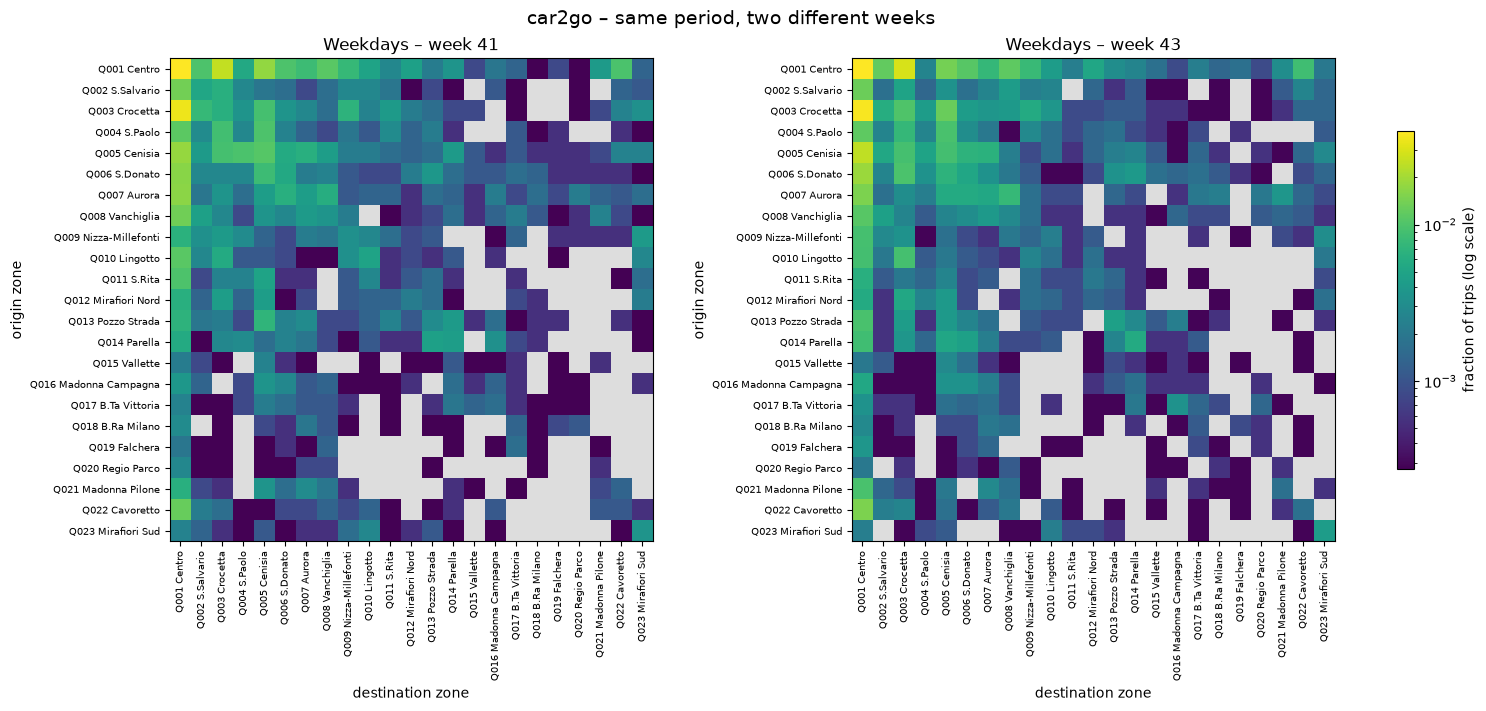

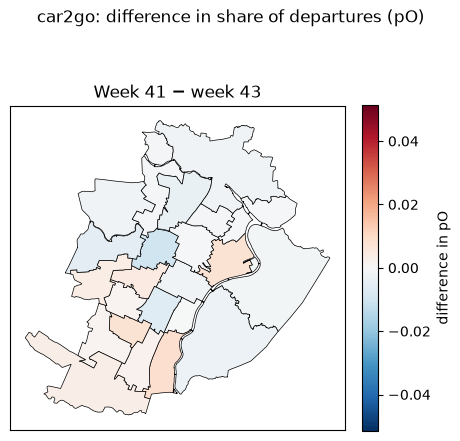

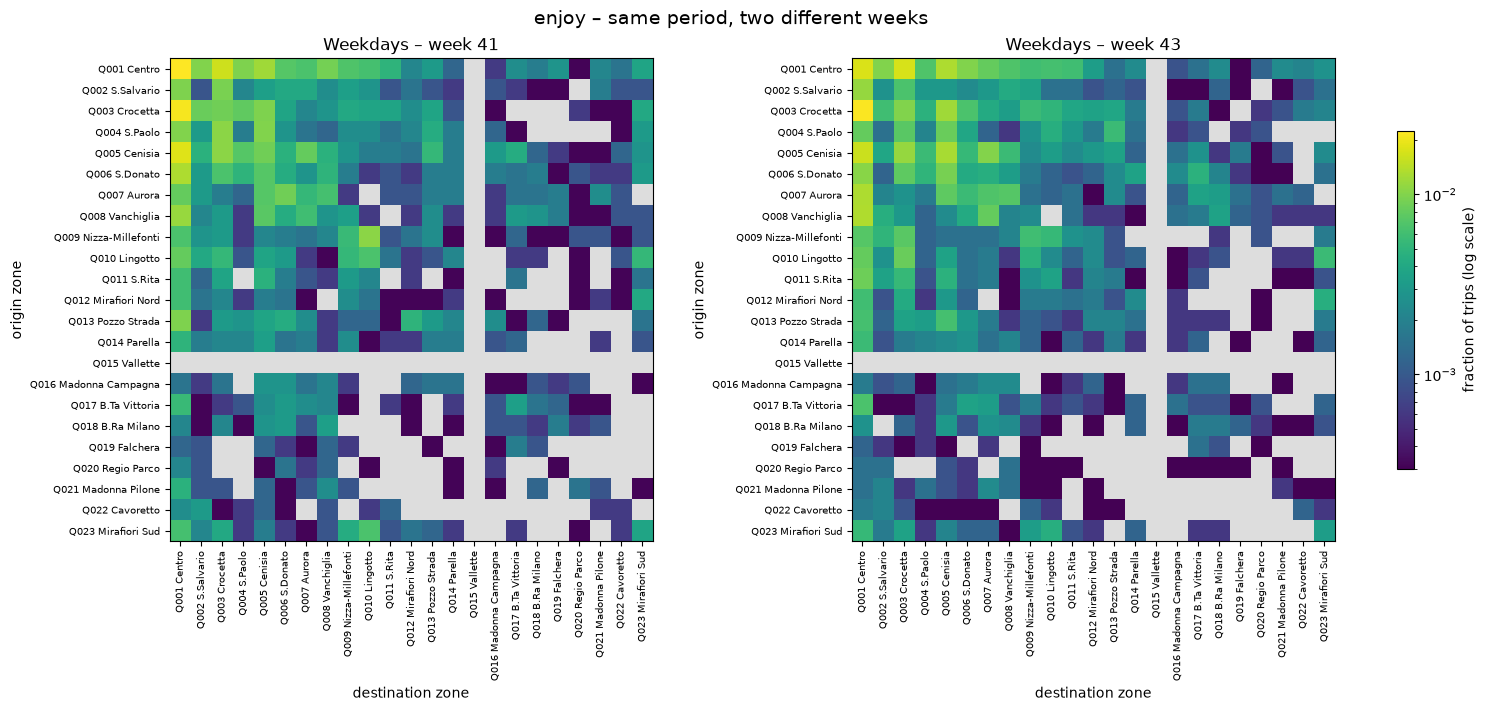

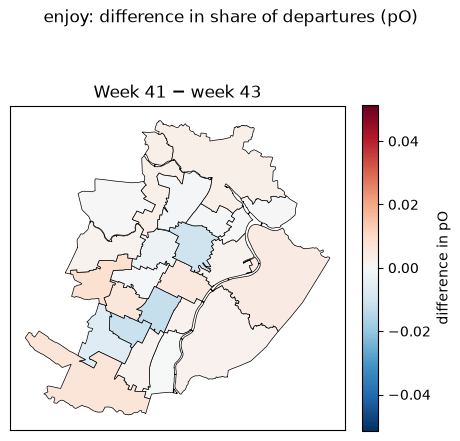

,count,mean,std,min,25%,50%,75%,max
vendor,,,,,,,,
car2go,15.0,18.180000,0.866190,16.4,17.65,18.40,18.65,19.9
enjoy,6.0,18.933333,1.136075,17.3,18.50,18.85,19.35,20.7


In [25]:
# same colour scale as the daytime − night-time map (Figure 2), so the differences are comparable
P = od_periods['car2go']
LIM = (P['Daytime'].sum(axis=1) - P['Night-time'].sum(axis=1)).abs().max()

od_weeks = {}
for vendor, df in trips.items():
    wd = select_period(df, days='weekdays')
    od_weeks[vendor] = {w: od_matrix(wd[wd.week == w], ZONES) for w in FULL_WEEKS[vendor]}
    A, B = od_weeks[vendor][WEEK_A], od_weeks[vendor][WEEK_B]
    plot_heatmaps({f'Weekdays – week {WEEK_A}': A, f'Weekdays – week {WEEK_B}': B},
                  f'{vendor} – same period, two different weeks', f'task1b_{vendor}_weeks')
    plot_zone_maps({f'Week {WEEK_A} − week {WEEK_B}': A.sum(axis=1) - B.sum(axis=1)},
                   f'{vendor}: difference in share of departures (pO)', f'task1b_{vendor}_map_diff',
                   'difference in pO', diverging=True, lim=LIM)

# TVD between all pairs of complete weeks
rows = [{'vendor': vendor, 'pair': f'{w1} vs {w2}', 'TVD (%)': tvd(mats[w1], mats[w2])}
        for vendor, mats in od_weeks.items() for w1, w2 in combinations(mats, 2)]
week_tvd = pd.DataFrame(rows).round(1)
week_tvd.groupby('vendor')['TVD (%)'].describe()

In [26]:
# reference for random noise: the same week split into two random halves
for vendor, df in trips.items():
    week = select_period(df, days='weekdays', weeks=[WEEK_A])
    half1 = week.sample(frac=0.5, random_state=0)
    half2 = week.drop(half1.index)
    print(f'{vendor} week {WEEK_A}, two random halves: TVD = {tvd(od_matrix(half1, ZONES), od_matrix(half2, ZONES)):.1f}%')

car2go week 41, two random halves: TVD = 23.8%
enjoy week 41, two random halves: TVD = 25.2%


In [27]:
# summary: different dates vs different periods
comparison = {}
for vendor, df in trips.items():
    week_a = select_period(df, weeks=[WEEK_A])
    P = od_periods[vendor]
    comparison[vendor] = {
        f'Weekdays: week {WEEK_A} vs {WEEK_B}':          tvd(od_weeks[vendor][WEEK_A], od_weeks[vendor][WEEK_B]),
        'Weekdays: all pairs of complete weeks (mean)': week_tvd[week_tvd.vendor == vendor]['TVD (%)'].mean(),
        f'Weekdays vs weekend, same week {WEEK_A}':       tvd(od_matrix(select_period(week_a, days='weekdays'), ZONES),
                                                           od_matrix(select_period(week_a, days='weekend'), ZONES)),
        'Weekdays vs weekends, all data':               tvd(P['Weekdays'], P['Weekends']),
        'Daytime vs night-time, all data':              tvd(P['Daytime'], P['Night-time']),
    }
comparison = pd.DataFrame(comparison).round(1)
comparison

,car2go,enjoy
Weekdays: week 41 vs 43,17.5,19.4
Weekdays: all pairs of complete weeks (mean),18.2,18.9
"Weekdays vs weekend, same week 41",29.8,30.9
"Weekdays vs weekends, all data",16.9,16.2
"Daytime vs night-time, all data",27.4,26.5


### Q1c – Same period and dates, Car2Go vs Enjoy
Weekdays of week WEEK_A for both platforms, then all dates in common.

59 common dates: 2017-09-01 -> 2017-10-31


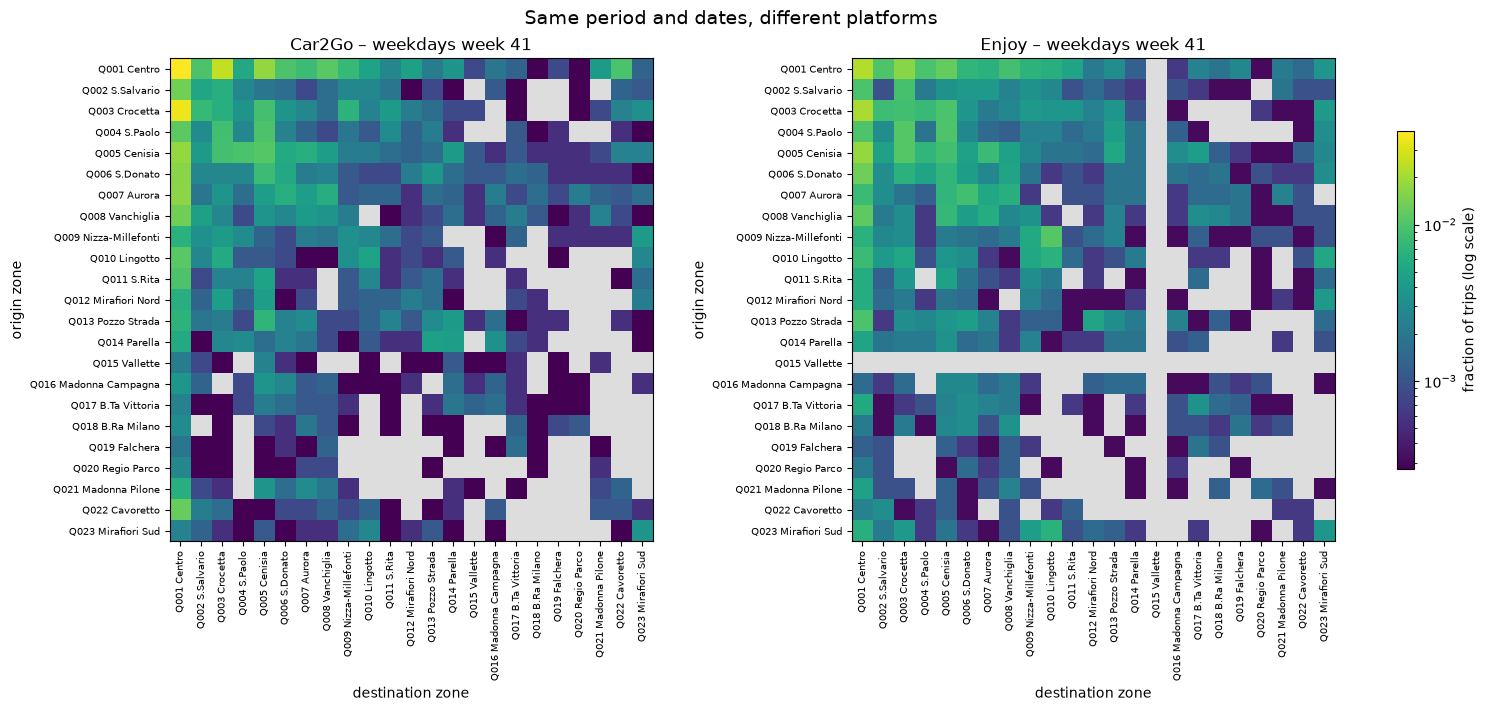

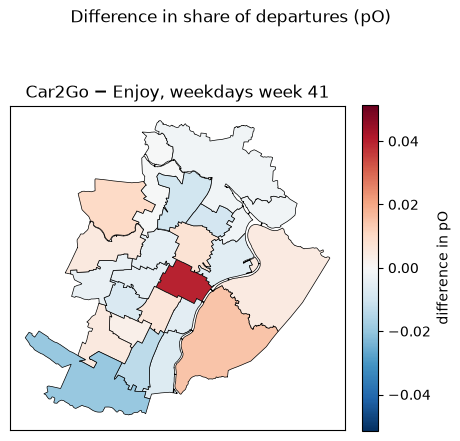

TVD Car2Go vs Enjoy, weekdays week 41: 26.1%
TVD Car2Go vs Enjoy, all common dates: 16.6%


In [28]:
common_dates = sorted(set(trips['car2go'].date) & set(trips['enjoy'].date))
same = {v: df[df.date.isin(common_dates)] for v, df in trips.items()}
print(f'{len(common_dates)} common dates: {common_dates[0]} -> {common_dates[-1]}')

od_vendor = {v: od_matrix(select_period(df, days='weekdays', weeks=[WEEK_A]), ZONES) for v, df in same.items()}
plot_heatmaps({f'Car2Go – weekdays week {WEEK_A}': od_vendor['car2go'],
               f'Enjoy – weekdays week {WEEK_A}': od_vendor['enjoy']},
              'Same period and dates, different platforms', 'task1c_heatmaps')
plot_zone_maps({f'Car2Go − Enjoy, weekdays week {WEEK_A}': od_vendor['car2go'].sum(axis=1) - od_vendor['enjoy'].sum(axis=1)},
               'Difference in share of departures (pO)', 'task1c_map_diff', 'difference in pO', diverging=True, lim=LIM)

print(f"TVD Car2Go vs Enjoy, weekdays week {WEEK_A}: {tvd(od_vendor['car2go'], od_vendor['enjoy']):.1f}%")
print(f"TVD Car2Go vs Enjoy, all common dates: {tvd(od_matrix(same['car2go'], ZONES), od_matrix(same['enjoy'], ZONES)):.1f}%")

In [29]:
# share of trips starting (pO) and ending (pD) in each zone, and OD pairs that differ the most
od_same = {v: od_matrix(df, ZONES) for v, df in same.items()}
coverage = pd.DataFrame({
    'zone': zone_labels(ZONES),
    'Car2Go pO (%)': od_same['car2go'].sum(axis=1).values * 100,
    'Enjoy pO (%)':  od_same['enjoy'].sum(axis=1).values * 100,
    'Car2Go pD (%)': od_same['car2go'].sum(axis=0).values * 100,
    'Enjoy pD (%)':  od_same['enjoy'].sum(axis=0).values * 100,
})
coverage['diff pO (p.p.)'] = coverage['Car2Go pO (%)'] - coverage['Enjoy pO (%)']
display(coverage.round(2).sort_values('diff pO (p.p.)', ascending=False))
top_changes(od_vendor['car2go'], od_vendor['enjoy'], 'Car2Go', 'Enjoy')

,zone,Car2Go pO (%),Enjoy pO (%),Car2Go pD (%),Enjoy pD (%),diff pO (p.p.)
0,Q001 Centro,16.90,13.15,22.73,16.04,3.75
21,Q022 Cavoretto,2.88,1.27,2.12,1.11,1.61
14,Q015 Vallette,1.15,0.00,1.09,0.01,1.15
20,Q021 Madonna Pilone,2.33,1.34,1.43,1.01,0.98
13,Q014 Parella,3.64,3.30,3.26,2.79,0.33
2,Q003 Crocetta,9.51,9.39,9.58,9.61,0.13
1,Q002 S.Salvario,5.66,5.56,5.44,5.60,0.10
18,Q019 Falchera,0.75,0.73,0.64,0.76,0.03
6,Q007 Aurora,6.67,6.67,5.66,6.30,0.00
15,Q016 Madonna Campagna,1.82,1.85,1.73,1.73,-0.03


,origin,destination,Car2Go (%),Enjoy (%),difference (p.p.)
0,Q001 Centro,Q001 Centro,3.96,2.25,1.71
1,Q003 Crocetta,Q001 Centro,3.47,2.13,1.34
2,Q022 Cavoretto,Q001 Centro,1.24,0.25,0.99
3,Q001 Centro,Q003 Crocetta,2.50,1.63,0.88
4,Q007 Aurora,Q001 Centro,1.68,0.81,0.87
5,Q001 Centro,Q022 Cavoretto,0.96,0.16,0.81
6,Q009 Nizza-Millefonti,Q010 Lingotto,0.28,1.06,-0.79
7,Q001 Centro,Q005 Cenisia,1.76,1.22,0.54
8,Q002 S.Salvario,Q002 S.Salvario,0.52,0.09,0.43
9,Q003 Crocetta,Q004 S.Paolo,0.36,0.78,-0.42


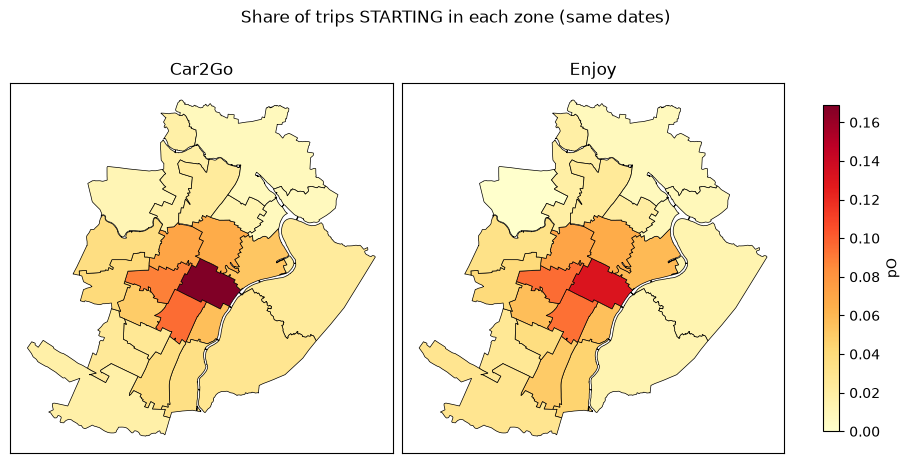

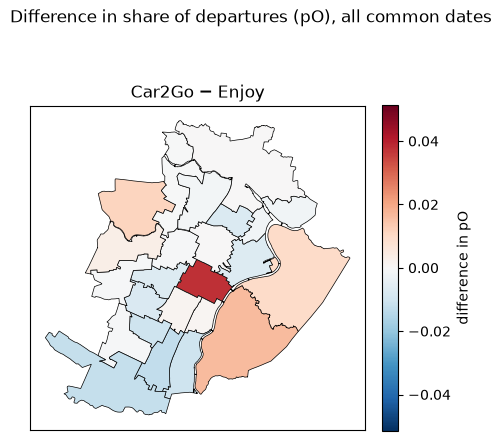

In [30]:
plot_zone_maps({'Car2Go': od_same['car2go'].sum(axis=1), 'Enjoy': od_same['enjoy'].sum(axis=1)},
               'Share of trips STARTING in each zone (same dates)', 'task1c_pO', 'pO')
plot_zone_maps({'Car2Go − Enjoy': od_same['car2go'].sum(axis=1) - od_same['enjoy'].sum(axis=1)},
               'Difference in share of departures (pO), all common dates', 'task1c_pO_diff',
               'difference in pO', diverging=True, lim=LIM)

## Question 2

Goal :
- Does 2 OD mat of my dataset are similars? 
- How does metrics react when we compare two random matrices or utterly different ones ?
- Which is the most pertinent metric to compare my OD?


We can test:
- L1
- L2
- Linf
- Spectral
- Jensen Shanon 

In [31]:
def compute_od_metrics(A, B):
    """
    Compute several distance metrics between two OD matrices
    """
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)

    if not np.isfinite(A).all() or not np.isfinite(B).all():
        raise ValueError("Matrices contain NaN or infinite values.")

    if (A < 0).any() or (B < 0).any():
        raise ValueError("OD matrices must be non-negative.")

    elif A.sum() <= 0 or B.sum() <= 0:
        raise ValueError("Matrices must have positive sums.")

    diff = A - B

    # L1
    d1 = np.abs(diff).sum()

    # L2
    d2 = np.linalg.norm(diff, ord="fro")

    # L-infinity
    d_inf = np.abs(diff).max()

    # Spectral norm
    d_spectral = np.linalg.norm(diff, ord=2)

    # Jensen-Shannon distance
    p = A.flatten()
    q = B.flatten()

    m = (p + q) / 2

    def kl_divergence(x, y):
        mask = x > 0
        return np.sum(x[mask] * np.log2(x[mask] / y[mask]))

    js_divergence = (kl_divergence(p, m) + kl_divergence(q, m))/2
    js_distance = np.sqrt(js_divergence)

    return {
        "L1": d1,
        "L2_Frobenius": d2,
        "L_inf": d_inf,
        "Spectral": d_spectral,
        "Jensen_Shannon": js_distance
    }


In [32]:
# Test 1: Two similar OD matrices

A_similar = np.array([
    [0.40, 0.10],
    [0.20, 0.30]
])

B_similar = np.array([
    [0.35, 0.15],
    [0.25, 0.25]
])


# Test 2: Two random probability matrices

rng = np.random.default_rng(42)

A_random = rng.random((4, 4))
A_random = A_random / A_random.sum()

B_random = rng.random((4, 4))
B_random = B_random / B_random.sum()


# Test 3: Completely dissimilar matrices

A_dissimilar = np.array([
    [1.0, 0.0],
    [0.0, 0.0]
])

B_dissimilar = np.array([
    [0.0, 0.0],
    [0.0, 1.0]
])


# Compute all metrics

tests = {
    "Similar matrices": (A_similar, B_similar),
    "Random matrices": (A_random, B_random),
    "Completely dissimilar": (A_dissimilar, B_dissimilar)
}

results = {}

for test, (A, B) in tests.items():
    results[test] = compute_od_metrics(A, B)

results_df = pd.DataFrame(results).T

print(results_df.round(4))

                           L1  L2_Frobenius   L_inf  Spectral  Jensen_Shannon
Similar matrices       0.2000        0.1000  0.0500    0.1000          0.0921
Random matrices        0.6298        0.1953  0.0938    0.1597          0.3852
Completely dissimilar  2.0000        1.4142  1.0000    1.0000          1.0000


In [33]:
rows = []
for vendor, P in od_periods.items():

    comparisons = [
        ('Weekdays vs Weekends', P['Weekdays'], P['Weekends']),
        ('Daytime vs Night-time', P['Daytime'], P['Night-time'])
    ]
    for comparison, A, B in comparisons:
        metrics = compute_od_metrics(A, B)
        rows.append({
            'vendor': vendor,
            'comparison': comparison,
            **metrics
        })

period_metrics = pd.DataFrame(rows).round(4)
display(period_metrics)

,vendor,comparison,L1,L2_Frobenius,L_inf,Spectral,Jensen_Shannon
0,car2go,Weekdays vs Weekends,0.3374,0.0323,0.0179,0.0276,0.1881
1,car2go,Daytime vs Night-time,0.5485,0.0575,0.0337,0.0489,0.2997
2,enjoy,Weekdays vs Weekends,0.3247,0.0258,0.0107,0.0186,0.1841
3,enjoy,Daytime vs Night-time,0.5305,0.0448,0.0185,0.0347,0.2889


In [34]:
from itertools import combinations
rows = []

for vendor, mats in od_weeks.items():
    for w1, w2 in combinations(mats.keys(), 2):

        metrics = compute_od_metrics(A, B)

        rows.append({
            'vendor': vendor,
            'pair': f'{w1} vs {w2}',
            **metrics
        })

week_metrics = pd.DataFrame(rows).round(4)
display(week_metrics)

,vendor,pair,L1,L2_Frobenius,L_inf,Spectral,Jensen_Shannon
0,car2go,37 vs 38,0.5305,0.0448,0.0185,0.0347,0.2889
1,car2go,37 vs 40,0.5305,0.0448,0.0185,0.0347,0.2889
2,car2go,37 vs 41,0.5305,0.0448,0.0185,0.0347,0.2889
3,car2go,37 vs 42,0.5305,0.0448,0.0185,0.0347,0.2889
4,car2go,37 vs 43,0.5305,0.0448,0.0185,0.0347,0.2889
5,car2go,38 vs 40,0.5305,0.0448,0.0185,0.0347,0.2889
6,car2go,38 vs 41,0.5305,0.0448,0.0185,0.0347,0.2889
7,car2go,38 vs 42,0.5305,0.0448,0.0185,0.0347,0.2889
8,car2go,38 vs 43,0.5305,0.0448,0.0185,0.0347,0.2889
9,car2go,40 vs 41,0.5305,0.0448,0.0185,0.0347,0.2889


In [35]:
def js_divergence(P, Q):
    """Jensen-Shannon divergence (base 2); the square root is the distance."""
    P = np.asarray(P, dtype=float); Q = np.asarray(Q, dtype=float)
    P = P / P.sum(); Q = Q / Q.sum()          # safety normalization
    M = (P + Q) / 2
    kl = lambda x, y: np.sum(x[x > 0] * np.log2(x[x > 0] / y[x > 0]))
    return np.sqrt((kl(P, M) + kl(Q, M)) / 2)

## Question 3: Compute OD matrices using UnipolTech dataset and IMQ dataset

### Loading IMQ Data

In [36]:
dfIMQ = pd.read_csv("./data/IMQ/IMQData_Torino.csv")
dfIMQ.head()

,ID_INT,GENDER,AGE,MOTIVATION,ORI_ZONE,DEP_HOUR,DST_ZONE,ARR_HOUR
0,8139335,1,2,5,Q005,02/02/17 10:00:00,Q023,02/02/17 10:20:00
1,8139641,2,4,4,Q002,02/02/17 16:30:00,Q023,02/02/17 16:50:00
2,8139830,1,2,4,Q019,02/02/17 14:30:00,Q019,02/02/17 14:50:00
3,8140616,1,2,9,Q003,02/02/17 20:00:00,Q005,02/02/17 20:30:00
4,8140678,2,3,4,Q009,02/02/17 09:00:00,Q009,02/02/17 09:10:00


In [37]:
def pct(OD):
    """Matrix normalization"""
    a = OD.to_numpy().astype(float)
    return 100 * a / max(a.sum(), 1)
def od_matrix(df, codes, origin="ORI_ZONE", dest="DST_ZONE", weight=None):
    """Matrice OD (comptages ou somme de poids), toutes zones conservées."""
    if weight is None:
        od = pd.crosstab(df[origin], df[dest])
    else:
        od = pd.crosstab(df[origin], df[dest], values=df[weight], aggfunc="sum").fillna(0)
    od = od.reindex(index=codes, columns=codes, fill_value=0)
    od.index.name, od.columns.name = "origin", "dest"
    return od

In [38]:
zones_raw = gpd.read_file("./data/IMQ/Zone/Zone_IMQ_TO_orig/Zone IMQ Prov_torino.shp", encoding="utf-8")
print("CRS d'origine :", zones_raw.crs)          # EPSG:23032 (ED50 / UTM 32N)

zones_imq = (
    zones_raw[zones_raw["Copia di C"].astype(str).str.match(r"^Q\d{3}$")]
    .rename(columns={"Copia di C": "zone_code"})[["zone_code", "zone_name", "geometry"]]
    .sort_values("zone_code")
    .reset_index(drop=True)
)
zones_imq["geometry"] = zones_imq.geometry.buffer(0)

zones_m = zones_imq.to_crs(32632)
zones_imq = zones_imq.to_crs(4326)
cent = zones_m.geometry.centroid.to_crs(4326)
zones_imq["cx"], zones_imq["cy"] = cent.x, cent.y
zones_imq["area_km2"] = (zones_m.area / 1e6).round(2)

codes = zones_imq["zone_code"].tolist()
print(len(zones_imq), "zones")
zones_imq.drop(columns="geometry").head()
OD_counts = od_matrix(dfIMQ, codes)                       
spost = pd.read_csv("./data/IMQ/IMQData/spostamentiTorino.csv", usecols=["TASSO_CAMP"])
assert len(spost) == len(dfIMQ)
dfIMQ["weight"] = spost["TASSO_CAMP"].values

CRS d'origine : EPSG:23032
23 zones


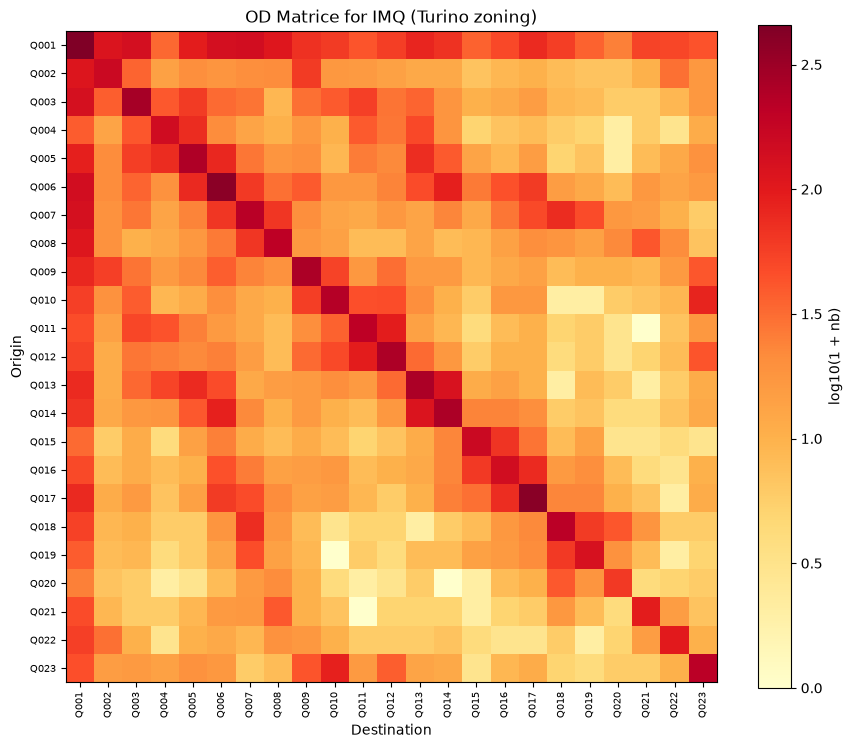

In [39]:
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(np.log10(OD_counts.to_numpy() + 1), cmap="YlOrRd")
ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=7)
ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=7)
ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
fig.colorbar(im, label="log10(1 + nb)")
ax.set_title("OD Matrice for IMQ (Turino zoning)")
plt.tight_layout(); plt.show()

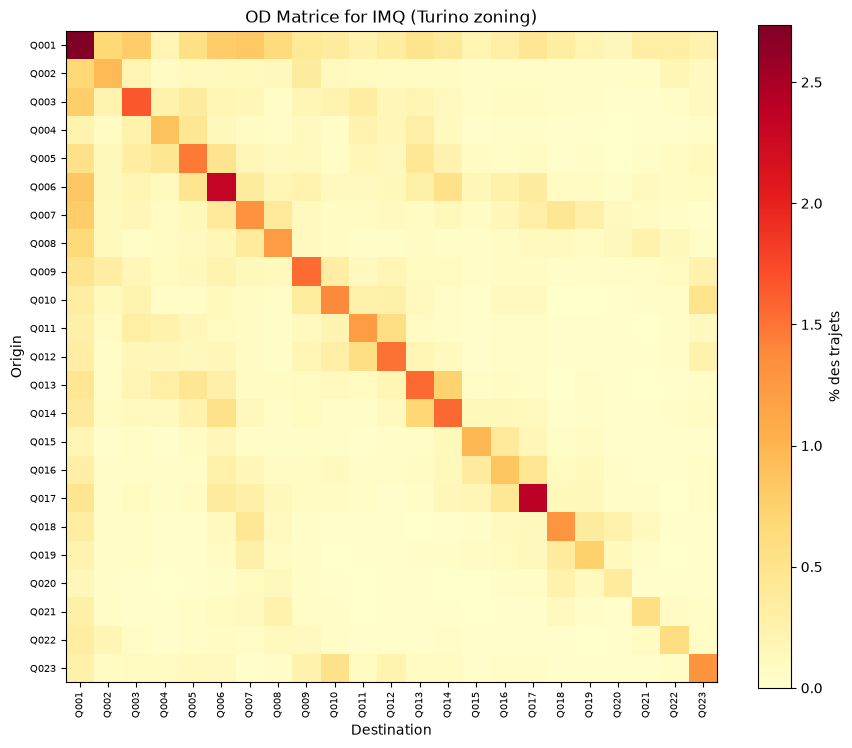

In [40]:
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(pct(OD_counts), cmap="YlOrRd")
ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=7)
ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=7)
ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
fig.colorbar(im, label="% des trajets")
ax.set_title("OD Matrice for IMQ (Turino zoning)")
plt.tight_layout(); plt.show()

### Loading Unipol Data

In [41]:
UNI_DIR = "./data/Unipoldata"   
trips_raw = pd.read_csv(f"{UNI_DIR}/Trips_OD_TO.csv", parse_dates=["istante_start", "istante_stop"])
info = pd.read_csv(f"{UNI_DIR}/Info_TO.csv")

trips_raw = trips_raw.rename(columns={
    "lon_start": "origin_lon", "lat_start": "origin_lat",
    "lon_stop": "destination_lon", "lat_stop": "destination_lat",
    "istante_start": "init_date", "istante_stop": "final_date",
})
trips_raw["duration_min"] = (trips_raw["final_date"] - trips_raw["init_date"]).dt.total_seconds() / 60

trips_raw.head()
T_START, T_END = pd.Timestamp("2024-09-02"), pd.Timestamp("2024-09-09")     

trips_uni = trips_raw.merge(info, on="id_veicolo", how="left")

mask = (
    (trips_uni.init_date >= T_START) & (trips_uni.init_date < T_END)         
    & (trips_uni.duration_min > 0)                                                                                  
)
trips_uni = trips_uni[mask].reset_index(drop=True)

In [42]:
def assign_zones(pts, zones):
    """Code de zone IMQ pour chaque point (NaN si hors de Turin)."""
    j = gpd.sjoin(pts, zones[["zone_code", "geometry"]], how="left", predicate="intersects")
    j = j[~j.index.duplicated(keep="first")]   
    return j["zone_code"].reindex(pts.index)

origins = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(trips_uni["origin_lon"], trips_uni["origin_lat"]), crs="EPSG:4326")
destinations = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(trips_uni["destination_lon"], trips_uni["destination_lat"]), crs="EPSG:4326")

trips_uni["ORI_ZONE"] = assign_zones(origins, zones_imq).values
trips_uni["DST_ZONE"] = assign_zones(destinations, zones_imq).values

trips_z = trips_uni.dropna(subset=["ORI_ZONE", "DST_ZONE"])
OD_uni = od_matrix(trips_z, codes)

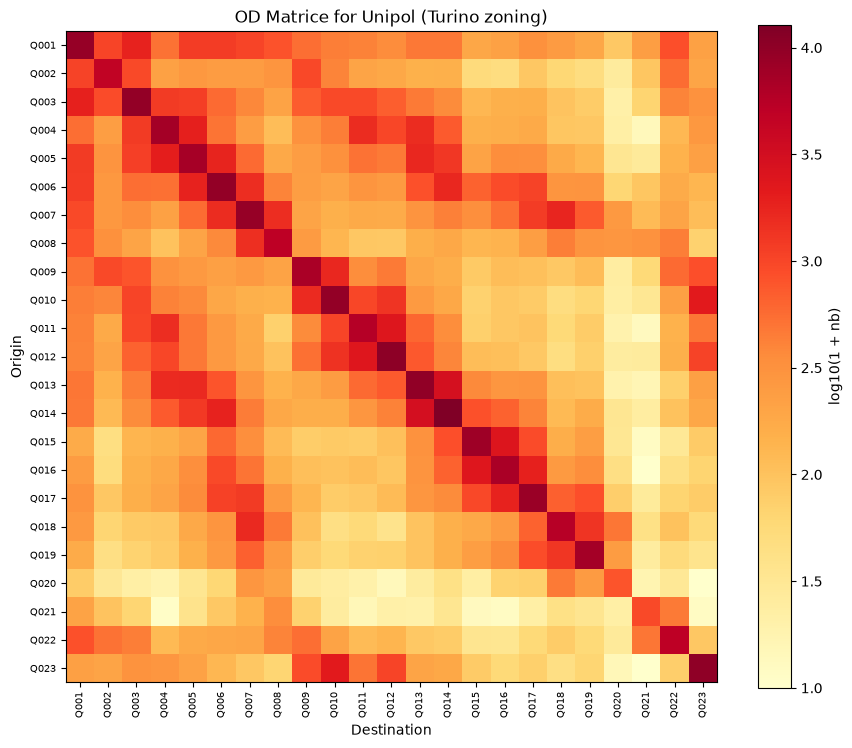

In [43]:
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(np.log10(OD_uni.to_numpy() + 1), cmap="YlOrRd")
ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=7)
ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=7)
ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
fig.colorbar(im, label="log10(1 + nb)")
ax.set_title("OD Matrice for Unipol (Turino zoning)")
plt.tight_layout(); plt.show()

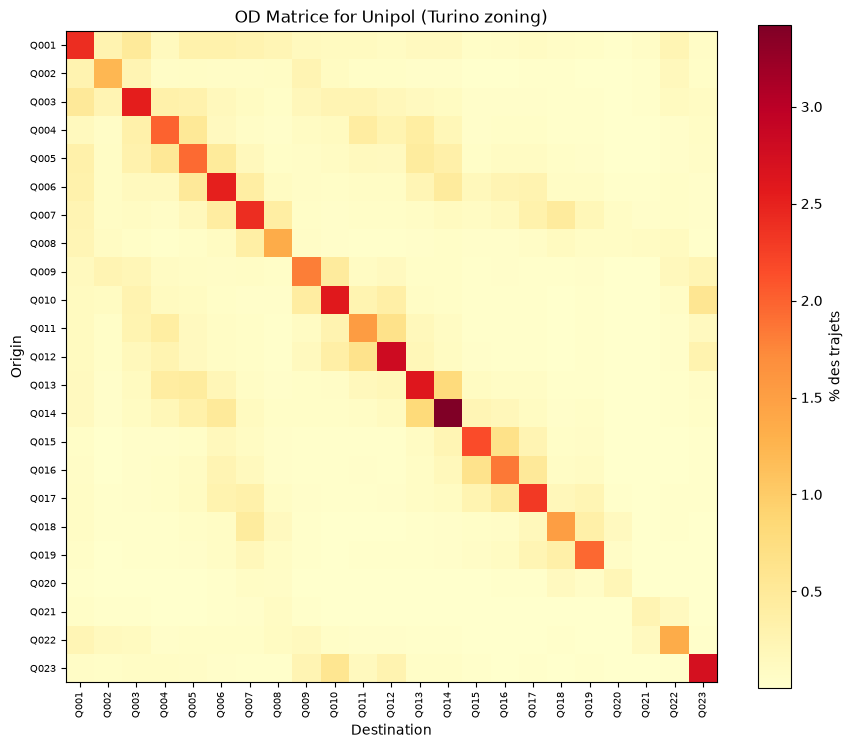

In [44]:
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(pct(OD_uni), cmap="YlOrRd")
ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=7)
ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=7)
ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
fig.colorbar(im, label="% des trajets")
ax.set_title("OD Matrice for Unipol (Turino zoning)")
plt.tight_layout(); plt.show()

### Raw Comparison

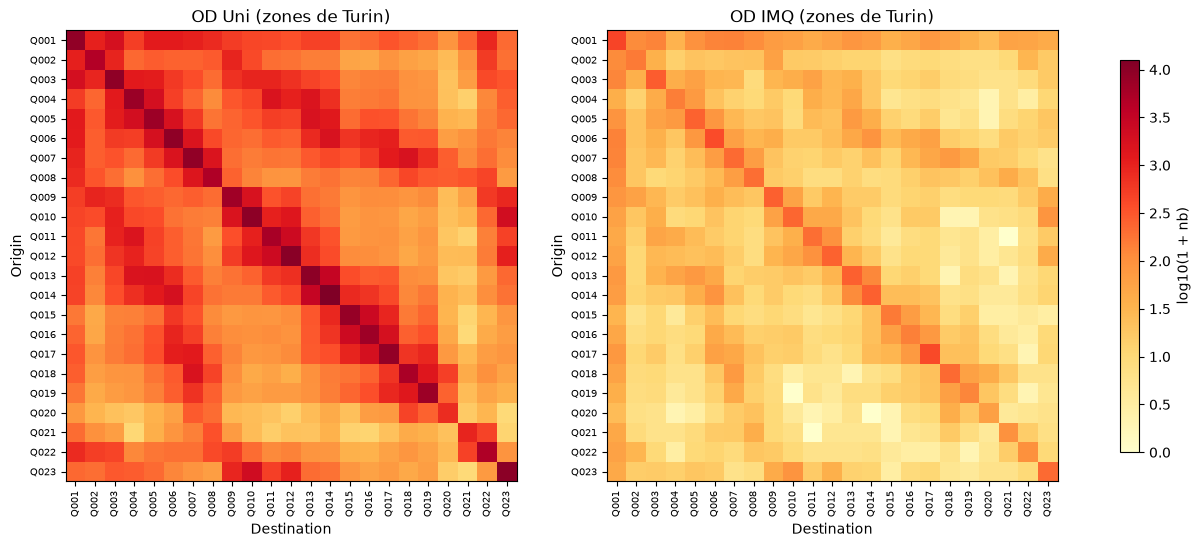

In [45]:
vmax_log = np.log10(max(OD_uni.to_numpy().max(), OD_counts.to_numpy().max()) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.8))

for ax, (name, M) in zip(axes, [("OD Uni", OD_uni), ("OD IMQ", OD_counts)]):
    im = ax.imshow(np.log10(M.to_numpy() + 1), cmap="YlOrRd", vmin=0, vmax=vmax_log)
    ax.set_xticks(range(len(M.columns))); ax.set_xticklabels(M.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(M.index)));  ax.set_yticklabels(M.index, fontsize=7)
    ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
    ax.set_title(f"{name} (zones de Turin)")

fig.colorbar(im, ax=axes, shrink=0.75, label="log10(1 + nb)")
plt.show()

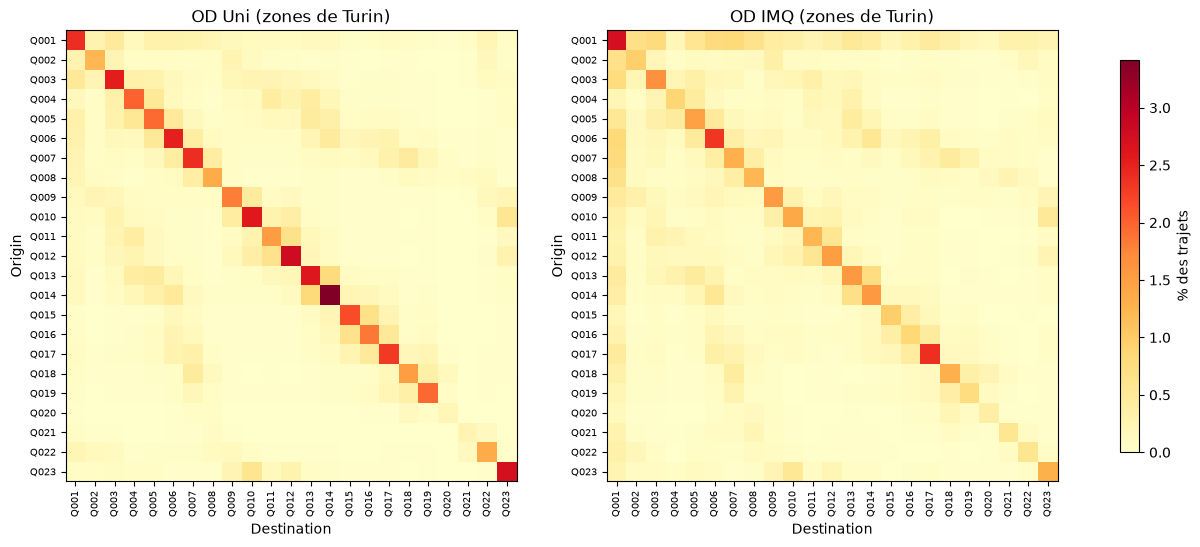

In [46]:
vmax = max(pct(OD_uni).max(), pct(OD_counts).max())

fig, axes = plt.subplots(1, 2, figsize=(16, 6.8))

for ax, (name, M) in zip(axes, [("OD Uni", OD_uni), ("OD IMQ", OD_counts)]):
    im = ax.imshow(pct(M), cmap="YlOrRd", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(M.columns))); ax.set_xticklabels(M.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(M.index)));  ax.set_yticklabels(M.index, fontsize=7)
    ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
    ax.set_title(f"{name} (zones de Turin)")

fig.colorbar(im, ax=axes, shrink=0.75, label="% des trajets")
plt.show()

### Question 3.a 

In [47]:
def _sjoin_zone(pts, zones):
    """Jointure spatiale : point à l'intérieur d'une zone -> zone_code (NaN sinon)."""
    j = gpd.sjoin(pts, zones[["zone_code", "geometry"]], how="left", predicate="within")
    j = j[~j.index.duplicated(keep="first")]          # un seul match par point
    return j["zone_code"].reindex(pts.index)


def _nearest_zone(pts_missing, zones):
    """Fallback : zone IMQ la plus proche (distances en projection métrique EPSG:32632)."""
    zp = zones.to_crs(32632)
    pm = pts_missing.to_crs(32632)
    j = gpd.sjoin_nearest(pm, zp[["zone_code", "geometry"]], how="left")
    j = j[~j.index.duplicated(keep="first")]
    return j["zone_code"].reindex(pts_missing.index)


def assign_imq_zones(df, zones, fallback="nearest",
                     lon_o="origin_lon", lat_o="origin_lat",
                     lon_d="destination_lon", lat_d="destination_lat"):
    """Ajoute les colonnes ORI_ZONE / DST_ZONE (codes IMQ) à un DataFrame de trajets."""
    d = df.copy()
    for prefix, lo, la in [("ORI", lon_o, lat_o), ("DST", lon_d, lat_d)]:
        pts = gpd.GeoDataFrame(
            geometry=gpd.points_from_xy(d[lo], d[la]),
            crs="EPSG:4326", index=d.index,
        )
        zone = _sjoin_zone(pts, zones)
        n_out = int(zone.isna().sum())
        if n_out and fallback == "nearest":
            zone.loc[zone.isna()] = _nearest_zone(pts[zone.isna()], zones)
            # print(f"{prefix} : {n_out} points hors des {len(zones)} zones IMQ -> zone la plus proche")
        else:
            pass
            # print(f"{prefix} : {n_out} points hors des {len(zones)} zones IMQ (NaN conservés)")
        d[f"{prefix}_ZONE"] = zone.to_numpy()
    return d

trips_uni_z = assign_imq_zones(trips_uni, zones_imq)   # Unipol filtré (cellule 26)


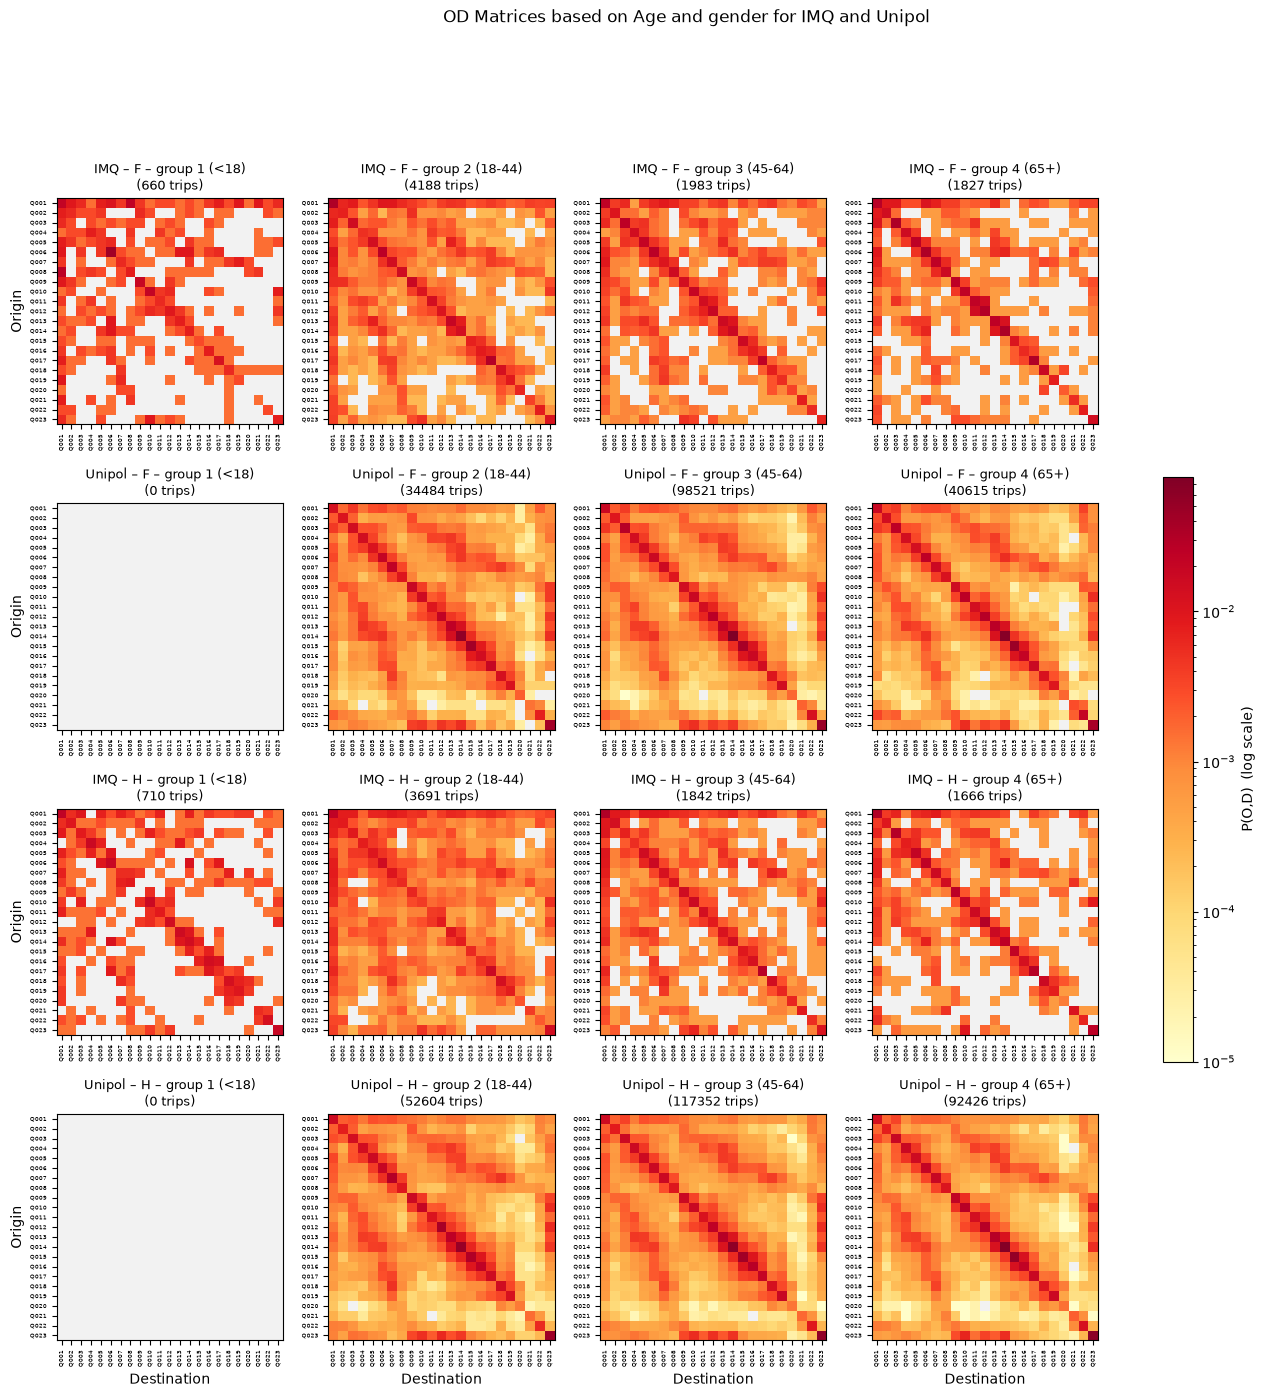

Jensen-Shannon distance IMQ and Unipol :


,group 1 (<18),group 2 (18-44),group 3 (45-64),group 4 (65+)
F,NaN,0.2896,0.2966,0.2948
H,NaN,0.3330,0.3290,0.2998


,IMQ,Unipol
group 1 (<18),0.083,0.000
group 2 (18-44),0.476,0.200
group 3 (45-64),0.231,0.495
group 4 (65+),0.211,0.305


In [48]:
AGE_BINS  = [0, 18, 45, 65, 120]     
AGE_LABEL = {1: "group 1 (<18)", 2: "group 2 (18-44)", 3: "group 3 (45-64)", 4: "group 4 (65+)"}
SEX_IMQ   = {1: "H", 2: "F"}           
SEX_UNI   = {"M": "H", "F": "F"}        

imq = dfIMQ.assign(sexe=dfIMQ["GENDER"].map(SEX_IMQ), age_cl=dfIMQ["AGE"]).dropna(subset=["sexe", "age_cl"])
imq["age_cl"] = imq["age_cl"].astype(int)

uni = trips_uni_z[(trips_uni_z["commerciale"] == "N") & trips_uni_z["genere"].isin(SEX_UNI)]
uni = uni.dropna(subset=["ORI_ZONE", "DST_ZONE", "eta_approx"]).copy()
uni["sexe"]   = uni["genere"].map(SEX_UNI)
uni["age_cl"] = pd.cut(uni["eta_approx"], AGE_BINS, labels=[1, 2, 3, 4], right=False).astype(int)

sexes, ages = ["F", "H"], [1, 2, 3, 4]
P, N = {}, {}
for src, df in [("IMQ", imq), ("Unipol", uni)]:
    for s in sexes:
        for a in ages:
            M = od_matrix(df[(df["sexe"] == s) & (df["age_cl"] == a)], codes).to_numpy(float)
            N[(src, s, a)] = int(M.sum())
            P[(src, s, a)] = M / M.sum() if M.sum() > 0 else M

rows = [(s, src) for s in sexes for src in ["IMQ", "Unipol"]]
vmax = max(m.max() for m in P.values())
cmap = plt.get_cmap("YlOrRd").copy(); cmap.set_bad("#f2f2f2")      

fig, axes = plt.subplots(len(rows), len(ages), figsize=(4.2 * len(ages), 3.8 * len(rows)), squeeze=False)
for i, (s, src) in enumerate(rows):
    for j, a in enumerate(ages):
        ax = axes[i][j]
        im = ax.imshow(P[(src, s, a)], cmap=cmap, norm=LogNorm(vmin=1e-5, vmax=vmax))
        ax.set_title(f"{src} – {s} – {AGE_LABEL[a]}\n({N[(src, s, a)]} trips)", fontsize=9)
        ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=4)
        ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=4)
        if i == len(rows) - 1: ax.set_xlabel("Destination")
        if j == 0: ax.set_ylabel("Origin")
fig.colorbar(im, ax=axes, shrink=0.5, label="P(O,D)  (log scale)")
fig.suptitle("OD Matrices based on Age and gender for IMQ and Unipol", y=0.995)
plt.show()

js = pd.DataFrame(
    {AGE_LABEL[a]: {s: (jensenshannon(P[("IMQ", s, a)].ravel(), P[("Unipol", s, a)].ravel())
                        if N[("IMQ", s, a)] and N[("Unipol", s, a)] else np.nan)
                    for s in sexes} for a in ages}
).round(4)
print("Jensen-Shannon distance IMQ and Unipol :")
display(js)

part = pd.DataFrame({src: {AGE_LABEL[a]: sum(N[(src, s, a)] for s in sexes) for a in ages}
                     for src in ["IMQ", "Unipol"]})
display((part / part.sum()).round(3))

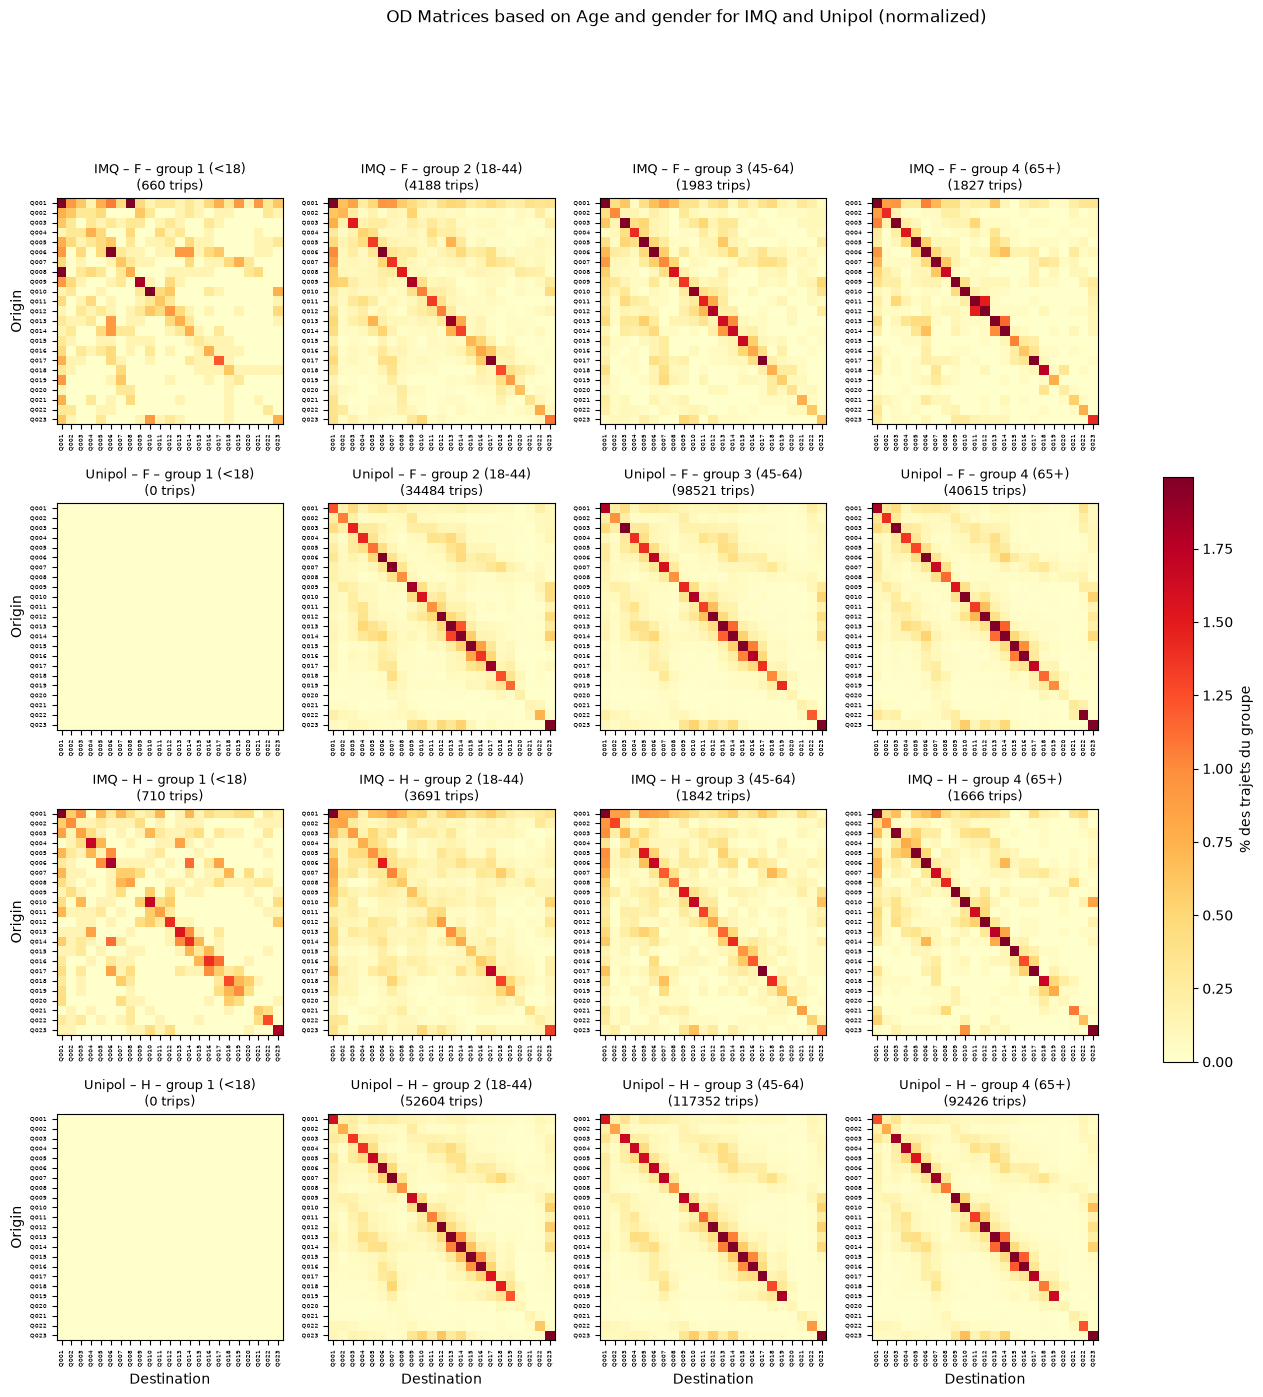

Jensen-Shannon distance IMQ and Unipol :


,group 1 (<18),group 2 (18-44),group 3 (45-64),group 4 (65+)
F,NaN,0.2896,0.2966,0.2948
H,NaN,0.3330,0.3290,0.2998


,IMQ,Unipol
group 1 (<18),0.083,0.000
group 2 (18-44),0.476,0.200
group 3 (45-64),0.231,0.495
group 4 (65+),0.211,0.305


In [49]:

AGE_BINS  = [0, 18, 45, 65, 120]
AGE_LABEL = {1: "group 1 (<18)", 2: "group 2 (18-44)", 3: "group 3 (45-64)", 4: "group 4 (65+)"}
SEX_IMQ   = {1: "H", 2: "F"}
SEX_UNI   = {"M": "H", "F": "F"}

imq = dfIMQ.assign(sexe=dfIMQ["GENDER"].map(SEX_IMQ), age_cl=dfIMQ["AGE"]).dropna(subset=["sexe", "age_cl"])
imq["age_cl"] = imq["age_cl"].astype(int)

uni = trips_uni_z[(trips_uni_z["commerciale"] == "N") & trips_uni_z["genere"].isin(SEX_UNI)]
uni = uni.dropna(subset=["ORI_ZONE", "DST_ZONE", "eta_approx"]).copy()
uni["sexe"]   = uni["genere"].map(SEX_UNI)
uni["age_cl"] = pd.cut(uni["eta_approx"], AGE_BINS, labels=[1, 2, 3, 4], right=False).astype(int)

sexes, ages = ["F", "H"], [1, 2, 3, 4]
P, N = {}, {}
for src, df in [("IMQ", imq), ("Unipol", uni)]:
    for s in sexes:
        for a in ages:
            M = od_matrix(df[(df["sexe"] == s) & (df["age_cl"] == a)], codes).to_numpy(float)
            N[(src, s, a)] = int(M.sum())
            P[(src, s, a)] = M / M.sum() if M.sum() > 0 else M    # somme = 1

rows = [(s, src) for s in sexes for src in ["IMQ", "Unipol"]]
vmax = 100 * np.percentile(np.concatenate([m.ravel() for m in P.values()]), 99)

fig, axes = plt.subplots(len(rows), len(ages), figsize=(4.2 * len(ages), 3.8 * len(rows)), squeeze=False)
for i, (s, src) in enumerate(rows):
    for j, a in enumerate(ages):
        ax = axes[i][j]
        im = ax.imshow(100 * P[(src, s, a)], cmap="YlOrRd", vmin=0, vmax=vmax)
        ax.set_title(f"{src} – {s} – {AGE_LABEL[a]}\n({N[(src, s, a)]} trips)", fontsize=9)
        ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=4)
        ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=4)
        if i == len(rows) - 1: ax.set_xlabel("Destination")
        if j == 0: ax.set_ylabel("Origin")
fig.colorbar(im, ax=axes, shrink=0.5, label="% des trajets du groupe")
fig.suptitle("OD Matrices based on Age and gender for IMQ and Unipol (normalized)", y=0.995)
plt.show()

js = pd.DataFrame(
    {AGE_LABEL[a]: {s: (jensenshannon(P[("IMQ", s, a)].ravel(), P[("Unipol", s, a)].ravel())
                        if N[("IMQ", s, a)] and N[("Unipol", s, a)] else np.nan)
                    for s in sexes} for a in ages}
).round(4)
print("Jensen-Shannon distance IMQ and Unipol :")
display(js)

part = pd.DataFrame({src: {AGE_LABEL[a]: sum(N[(src, s, a)] for s in sexes) for a in ages}
                     for src in ["IMQ", "Unipol"]})
display((part / part.sum()).round(3))

### List of Motivation
1. Go to work 
2. Working Reason
3. Study
4. Shopping
5. Bring Someone
6. Cures/Medical Visits
7. Sport or Leisure
8. Going back home
9. Visiting Relatives
10. Other
11. Going back home on the day of the Interview

Motivations présentes : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)] | n trajets par motif : {1: 2203, 2: 348, 3: 569, 4: 2635, 5: 759, 6: 405, 7: 1442, 8: 7551, 9: 510, 10: 23, 11: 122}


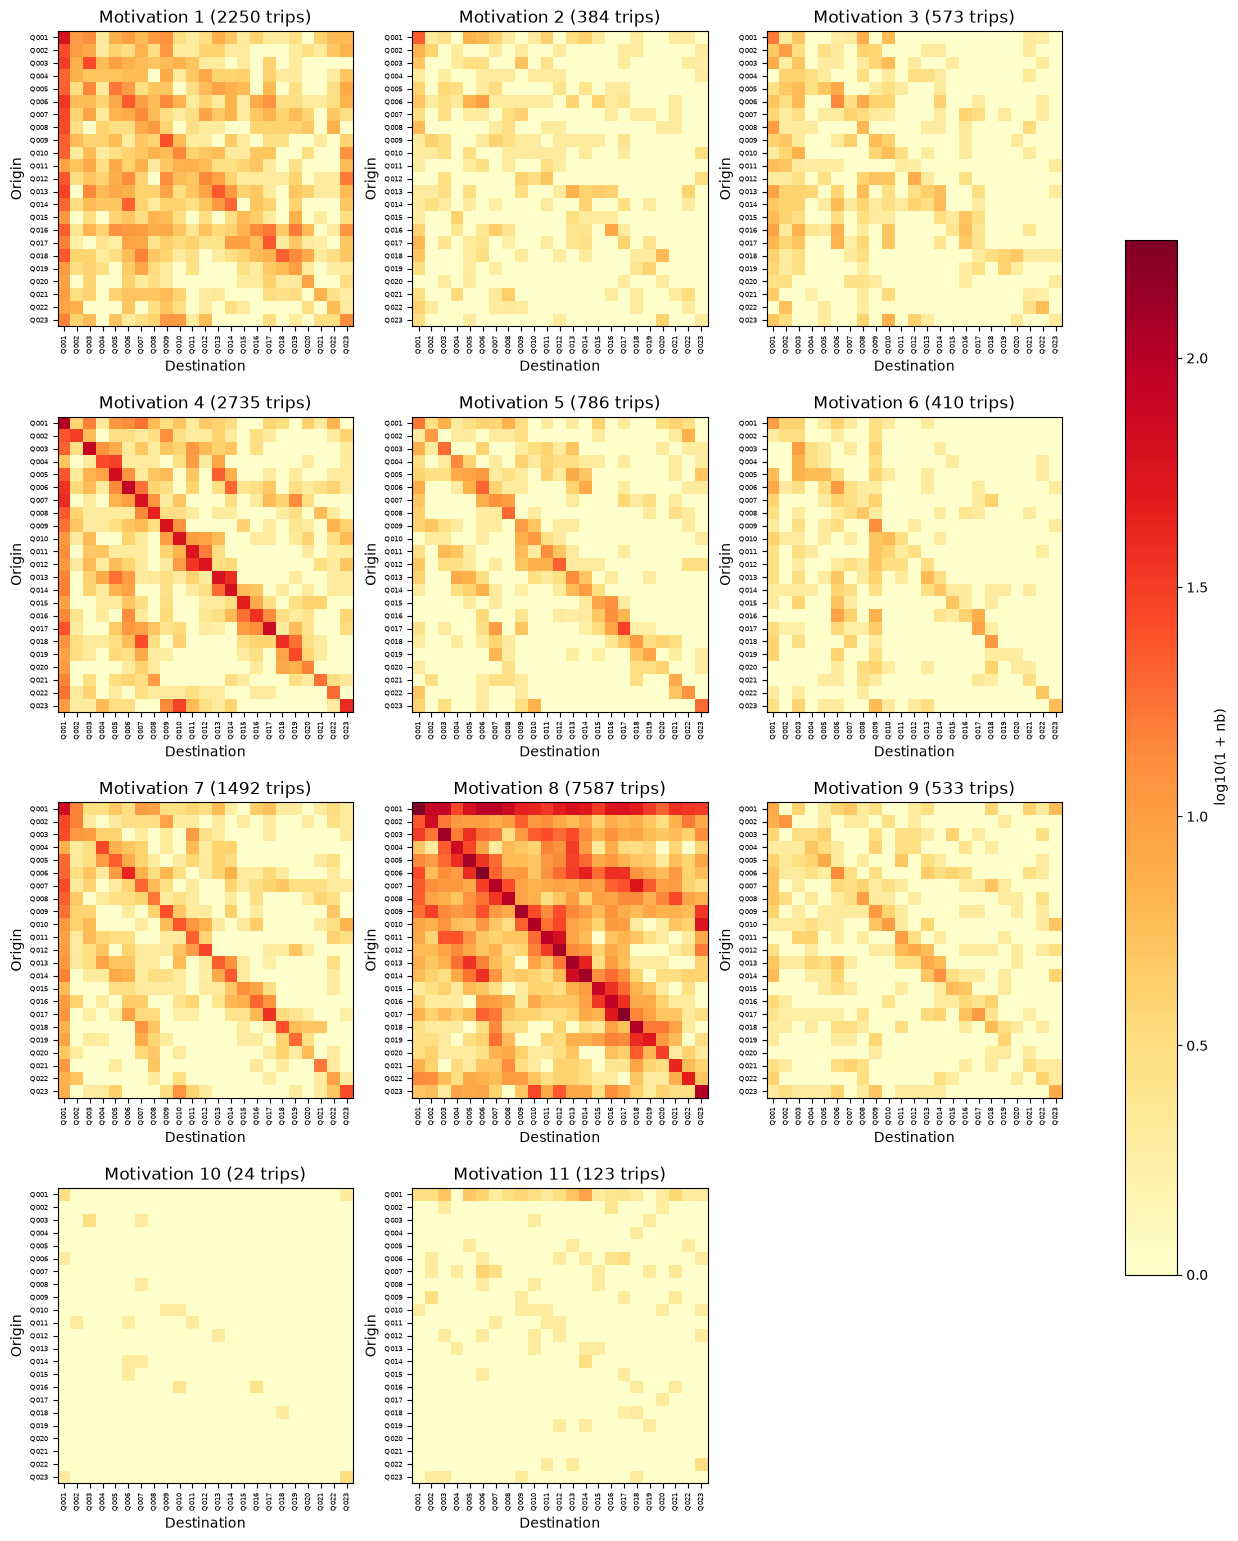

In [50]:
# OD Based on Motivation
motifs = sorted(dfIMQ["MOTIVATION"].dropna().astype(int).unique())
print("Motivations présentes :", motifs, "| n trajets par motif :",
      dfIMQ["MOTIVATION"].value_counts().reindex(motifs).to_dict())

OD_motif = {
    m: od_matrix(dfIMQ[dfIMQ["MOTIVATION"] == m], codes, weight="weight")
    for m in motifs
}

# affichage : une heatmap par motivation, échelle log commune
ncols, nrows = 3, int(np.ceil(len(motifs) / 3))
vmax = np.log10(max(OD.to_numpy().max() for OD in OD_motif.values()) + 1)

fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 4.8 * nrows), squeeze=False)
for k, m in enumerate(motifs):
    ax, OD = axes[k // ncols][k % ncols], OD_motif[m]
    im = ax.imshow(np.log10(OD.to_numpy() + 1), cmap="YlOrRd", vmin=0, vmax=vmax)
    ax.set_title(f"Motivation {m} ({OD.to_numpy().sum():.0f} trips)")
    ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=5)
    ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=5)
    ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
for k in range(len(motifs), nrows * ncols):
    axes[k // ncols][k % ncols].axis("off")
fig.colorbar(im, ax=axes, shrink=0.7, label="log10(1 + nb)")
plt.show()

Motivations présentes : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)] | n trajets par motif : {1: 2203, 2: 348, 3: 569, 4: 2635, 5: 759, 6: 405, 7: 1442, 8: 7551, 9: 510, 10: 23, 11: 122}


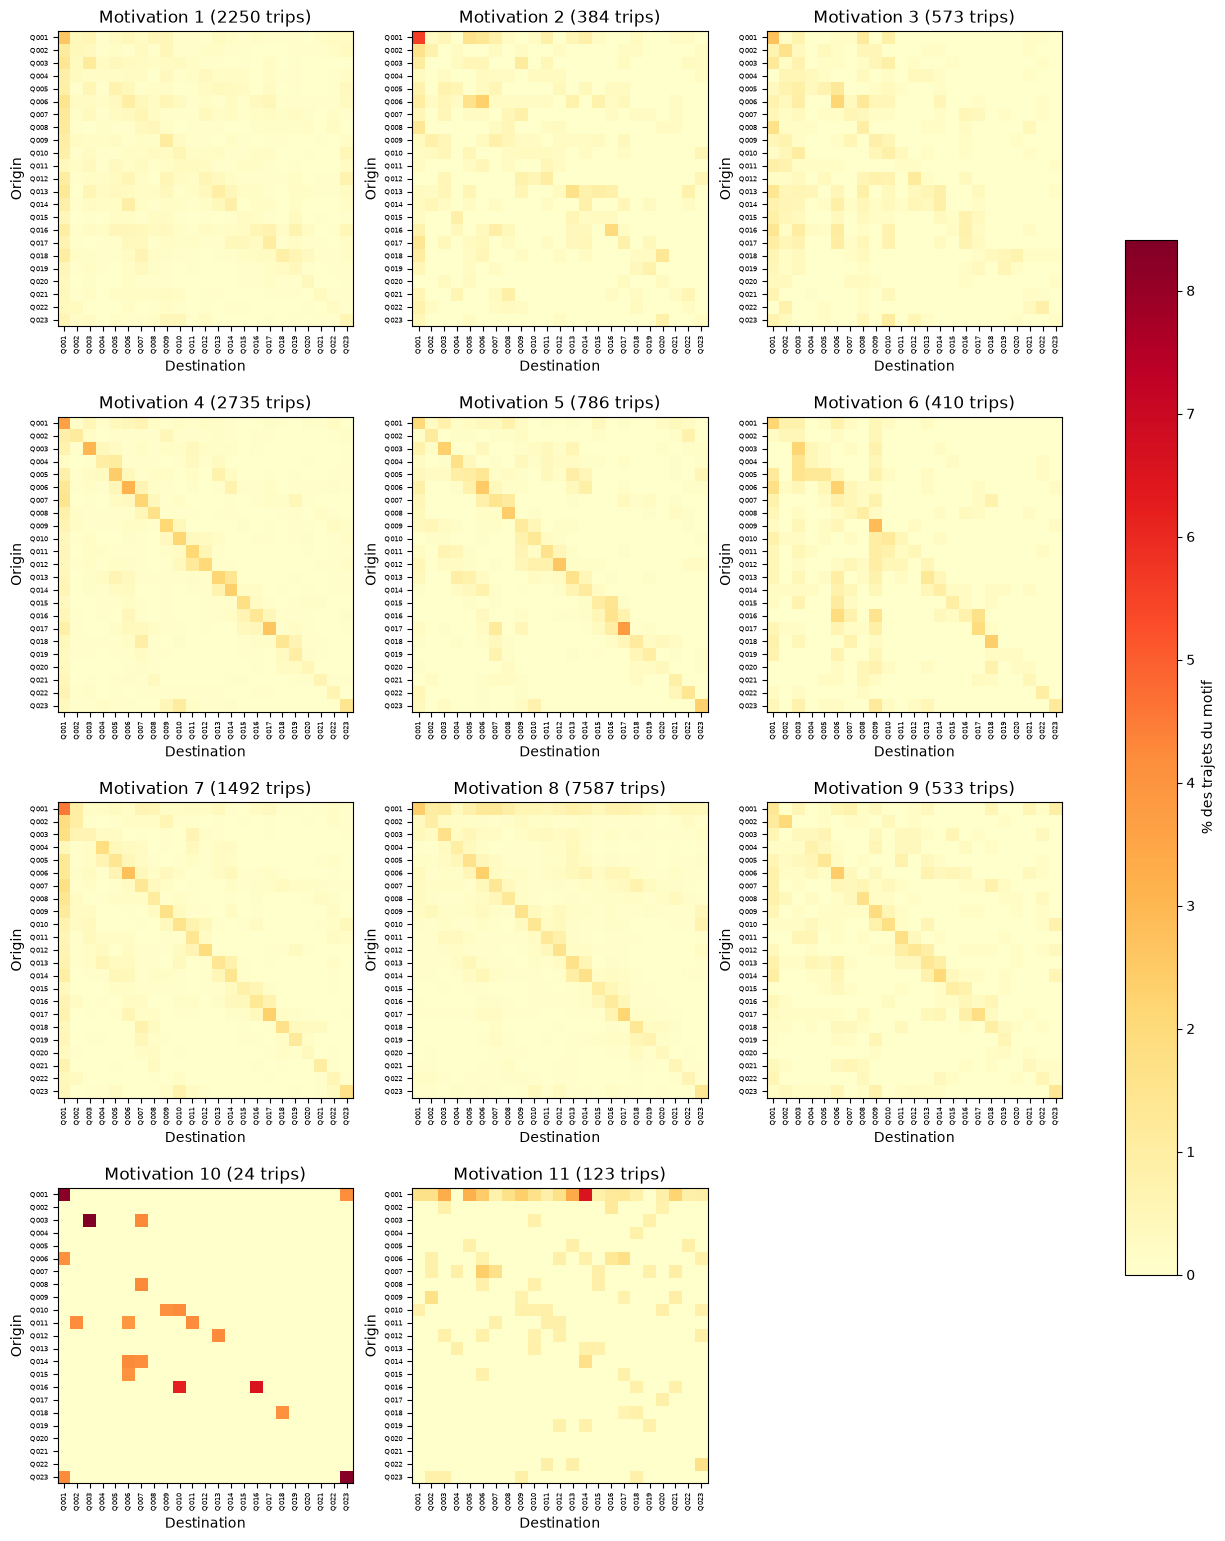

In [51]:
# OD Based on Motivation
motifs = sorted(dfIMQ["MOTIVATION"].dropna().astype(int).unique())
print("Motivations présentes :", motifs, "| n trajets par motif :",
      dfIMQ["MOTIVATION"].value_counts().reindex(motifs).to_dict())

OD_motif = {
    m: od_matrix(dfIMQ[dfIMQ["MOTIVATION"] == m], codes, weight="weight")
    for m in motifs
}

ncols, nrows = 3, int(np.ceil(len(motifs) / 3))
vmax = max(pct(OD).max() for OD in OD_motif.values())

fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 4.8 * nrows), squeeze=False)
for k, m in enumerate(motifs):
    ax, OD = axes[k // ncols][k % ncols], OD_motif[m]
    im = ax.imshow(pct(OD), cmap="YlOrRd", vmin=0, vmax=vmax)
    ax.set_title(f"Motivation {m} ({OD.to_numpy().sum():.0f} trips)")
    ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=5)
    ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=5)
    ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
for k in range(len(motifs), nrows * ncols):
    axes[k // ncols][k % ncols].axis("off")
fig.colorbar(im, ax=axes, shrink=0.7, label="% des trajets du motif")
plt.show()

### Question 3.b

Sex : [np.int64(1), np.int64(2)] | Age : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
sex 1 x age 1 : 710 trips (4.3%)
sex 1 x age 2 : 3691 trips (22.3%)
sex 1 x age 3 : 1842 trips (11.1%)
sex 1 x age 4 : 1666 trips (10.1%)
sex 2 x age 1 : 660 trips (4.0%)
sex 2 x age 2 : 4188 trips (25.3%)
sex 2 x age 3 : 1983 trips (12.0%)
sex 2 x age 4 : 1827 trips (11.0%)


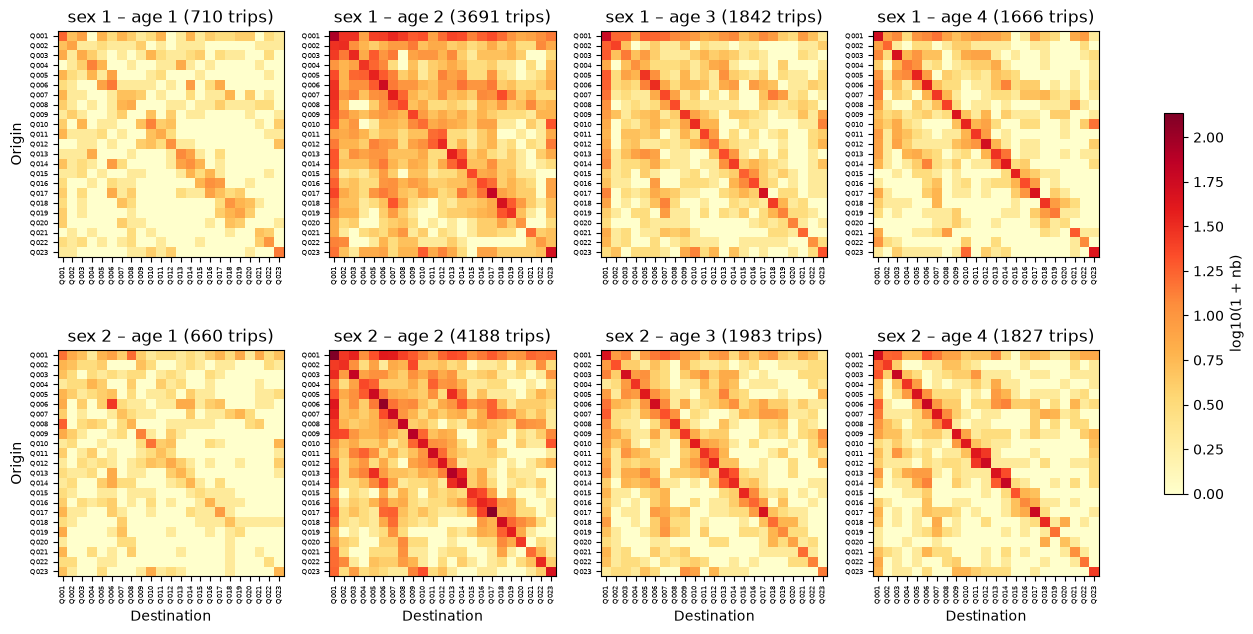

In [52]:
sexe_label = {1: "sex 1", 2: "sex 2"}         
age_label  = {1: "age 1", 2: "age 2", 3: "age 3", 4: "age 4"}

sexes = sorted(dfIMQ["GENDER"].dropna().astype(int).unique())
ages  = sorted(dfIMQ["AGE"].dropna().astype(int).unique())
print("Sex :", sexes, "| Age :", ages)

OD_sexe_age = {}
for s in sexes:
    for a in ages:
        df_sa = dfIMQ[(dfIMQ["GENDER"] == s) & (dfIMQ["AGE"] == a)]
        OD_sexe_age[(s, a)] = od_matrix(df_sa, codes)
        print(f"{sexe_label.get(s, s)} x {age_label.get(a, a)} : {len(df_sa)} trips ({len(df_sa)/len(dfIMQ):.1%})")
vmax = np.log10(max(OD.to_numpy().max() for OD in OD_sexe_age.values()) + 1)

fig, axes = plt.subplots(len(sexes), len(ages), figsize=(4.2 * len(ages), 3.8 * len(sexes)), squeeze=False)

for i, s in enumerate(sexes):
    for j, a in enumerate(ages):
        ax, OD = axes[i][j], OD_sexe_age[(s, a)]
        im = ax.imshow(np.log10(OD.to_numpy() + 1), cmap="YlOrRd", vmin=0, vmax=vmax)
        ax.set_title(f"{sexe_label.get(s, s)} – {age_label.get(a, a)} ({OD.to_numpy().sum():.0f} trips)")
        ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=5)
        ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=5)
        if i == len(sexes) - 1: ax.set_xlabel("Destination")
        if j == 0: ax.set_ylabel("Origin")

fig.colorbar(im, ax=axes, shrink=0.65, label="log10(1 + nb)")
plt.show()



sex 1 x age 1 : 710 trajets (4.3%)
sex 1 x age 2 : 3691 trajets (22.3%)
sex 1 x age 3 : 1842 trajets (11.1%)
sex 1 x age 4 : 1666 trajets (10.1%)
sex 2 x age 1 : 660 trajets (4.0%)
sex 2 x age 2 : 4188 trajets (25.3%)
sex 2 x age 3 : 1983 trajets (12.0%)
sex 2 x age 4 : 1827 trajets (11.0%)


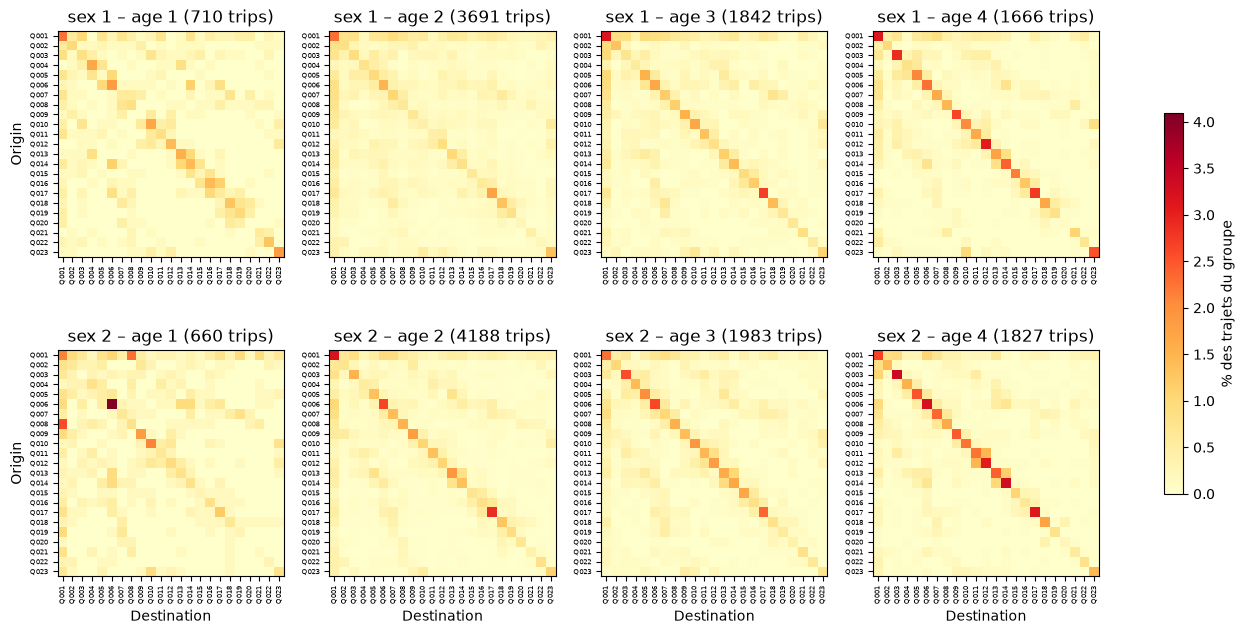

In [53]:

OD_sexe_age = {}
for s in sexes:
    for a in ages:
        df_sa = dfIMQ[(dfIMQ["GENDER"] == s) & (dfIMQ["AGE"] == a)]
        OD_sexe_age[(s, a)] = od_matrix(df_sa, codes)
        print(f"{sexe_label.get(s, s)} x {age_label.get(a, a)} : {len(df_sa)} trajets ({len(df_sa)/len(dfIMQ):.1%})")

vmax = max(pct(OD).max() for OD in OD_sexe_age.values())

fig, axes = plt.subplots(len(sexes), len(ages), figsize=(4.2 * len(ages), 3.8 * len(sexes)), squeeze=False)

for i, s in enumerate(sexes):
    for j, a in enumerate(ages):
        ax, OD = axes[i][j], OD_sexe_age[(s, a)]
        im = ax.imshow(pct(OD), cmap="YlOrRd", vmin=0, vmax=vmax)
        ax.set_title(f"{sexe_label.get(s, s)} – {age_label.get(a, a)} ({OD.to_numpy().sum():.0f} trips)")
        ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=5)
        ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=5)
        if i == len(sexes) - 1: ax.set_xlabel("Destination")
        if j == 0: ax.set_ylabel("Origin")

fig.colorbar(im, ax=axes, shrink=0.65, label="% des trajets du groupe")
plt.show()

Sex keys: [np.int64(1), np.int64(2)] | Age keys: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

=== JS distance between age groups – sex 1 ===
        age 1   age 2   age 3   age 4
age 1  0.0000  0.6835  0.6866  0.6913
age 2  0.6835  0.0000  0.5776  0.6311
age 3  0.6866  0.5776  0.0000  0.6054
age 4  0.6913  0.6311  0.6054  0.0000

=== JS distance between age groups – sex 2 ===
        age 1   age 2   age 3   age 4
age 1  0.0000  0.6565  0.6998  0.7160
age 2  0.6565  0.0000  0.5485  0.5890
age 3  0.6998  0.5485  0.0000  0.5873
age 4  0.7160  0.5890  0.5873  0.0000


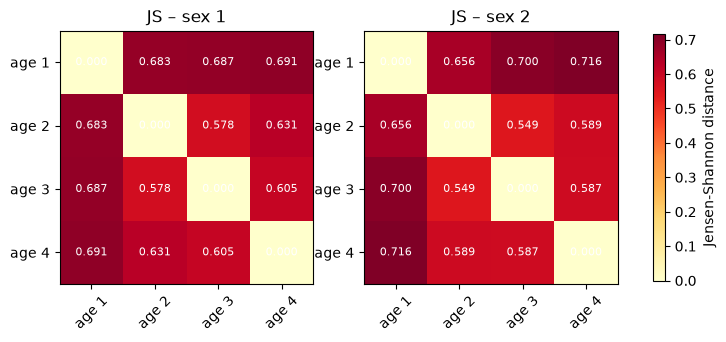

In [54]:
def to_dist(OD):
    """Flatten the OD matrix and normalize it into a probability distribution."""
    v = OD.to_numpy().astype(float).ravel()
    return v / v.sum()

sexes_k = sorted({k[0] for k in OD_sexe_age})
ages_k  = sorted({k[1] for k in OD_sexe_age})
print("Sex keys:", sexes_k, "| Age keys:", ages_k)

JS_same_sex = {}   # {sex: DataFrame (ages x ages)}

for s in sexes_k:
    M = pd.DataFrame(0.0, index=ages_k, columns=ages_k)
    for a1, a2 in combinations(ages_k, 2):
        P = to_dist(OD_sexe_age[(s, a1)])
        Q = to_dist(OD_sexe_age[(s, a2)])
        d = np.sqrt(js_divergence(P, Q))   # remove sqrt if js_divergence already returns the distance
        M.loc[a1, a2] = M.loc[a2, a1] = d
    JS_same_sex[s] = M

    print(f"\n=== JS distance between age groups – {sexe_label.get(s, s)} ===")
    print(M.rename(index=age_label, columns=age_label).round(4))

vmax_js = max(M.to_numpy().max() for M in JS_same_sex.values())

fig, axes = plt.subplots(1, len(sexes_k), figsize=(4.5 * len(sexes_k), 4), squeeze=False)
for k, s in enumerate(sexes_k):
    ax, M = axes[0][k], JS_same_sex[s]
    im = ax.imshow(M.to_numpy(), cmap="YlOrRd", vmin=0, vmax=vmax_js)
    ax.set_title(f"JS – {sexe_label.get(s, s)}")
    ax.set_xticks(range(len(ages_k))); ax.set_xticklabels([age_label.get(a, a) for a in ages_k], rotation=45)
    ax.set_yticks(range(len(ages_k))); ax.set_yticklabels([age_label.get(a, a) for a in ages_k])
    for i in range(len(ages_k)):
        for j in range(len(ages_k)):
            ax.text(j, i, f"{M.iloc[i, j]:.3f}", ha="center", va="center", color="white", fontsize=8)

fig.colorbar(im, ax=axes, shrink=0.8, label="Jensen-Shannon distance")
plt.show()

### Question 3.c

In [55]:
def load_trips_with_loc(coll, city="Torino"):
    pipe = [
        {"$match": {"city": city, "driving.distance": {"$gt": 0}}},
        {"$project": {
            "_id": 0, "plate": 1,
            "init_date": 1, "final_date": 1, "init_time": 1, "final_time": 1,
            "init_loc": 1, "final_loc": 1,
            "drv_dur": "$driving.duration", "drv_dist": "$driving.distance",
        }},
    ]
    df = pd.DataFrame(coll.aggregate(pipe, allowDiskUse=True))
    df["rental_min"] = (df["final_time"] - df["init_time"]) / 60
    df["drv_dist_km"] = df["drv_dist"] / 1000
    df["init_date"] = pd.to_datetime(df["init_date"])

    df["origin_lon"] = df["init_loc"].apply(lambda x: x["coordinates"][0])
    df["origin_lat"] = df["init_loc"].apply(lambda x: x["coordinates"][1])
    df["destination_lon"] = df["final_loc"].apply(lambda x: x["coordinates"][0])
    df["destination_lat"] = df["final_loc"].apply(lambda x: x["coordinates"][1])
    return df.drop(columns=["init_loc", "final_loc"])


trips_c2g = load_trips_with_loc(pb_coll)
trips_enjoy = load_trips_with_loc(pb_coll_enjoy)

In [56]:
trips_c2g_z = assign_imq_zones(trips_c2g, zones_imq)
trips_enjoy_z = assign_imq_zones(trips_enjoy, zones_imq)
def od_matrix_safe(df, codes):
    m = df["ORI_ZONE"].notna() & df["DST_ZONE"].notna()
    if (~m).any():
        pass
    return od_matrix(df[m], codes)


OD_imq = OD_counts                      
OD_uni = od_matrix_safe(trips_uni_z, codes)
OD_c2g = od_matrix_safe(trips_c2g_z, codes)
OD_enjoy = od_matrix_safe(trips_enjoy_z, codes)

P_imq, P_uni, P_c2g, P_enjoy = (
    OD / OD.to_numpy().sum() for OD in [OD_imq, OD_uni, OD_c2g, OD_enjoy]
)

matrices = [OD_imq, OD_uni, OD_c2g, OD_enjoy]
recap = pd.DataFrame(
    {
        "trips": [int(OD.to_numpy().sum()) for OD in matrices],
        "Same zone part": [
            f"{np.trace(OD.to_numpy()) / OD.to_numpy().sum():.1%}" for OD in matrices
        ],
    },
    index=["IMQ", "Unipol", "Car2Go", "Enjoy"],
)
display(recap)



,trips,Same zone part
IMQ,16567,30.4%
Unipol,480078,46.9%
Car2Go,39190,10.2%
Enjoy,35726,8.3%


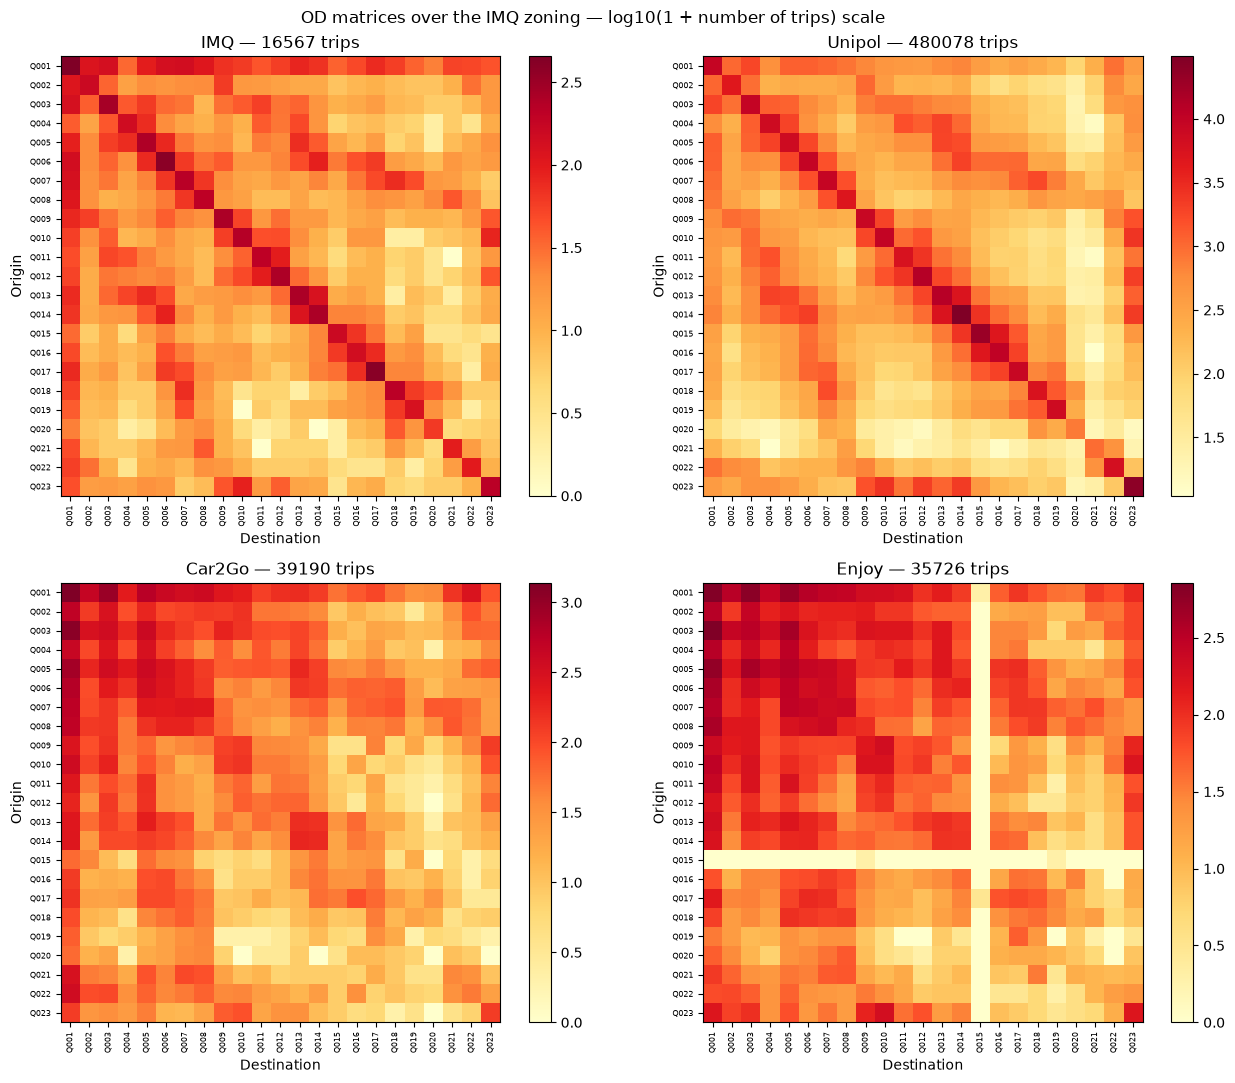

In [57]:
mats = {"IMQ": OD_imq, "Unipol": OD_uni, "Car2Go": OD_c2g, "Enjoy": OD_enjoy}

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (name, OD) in zip(axes.flat, mats.items()):
    im = ax.imshow(np.log10(OD.to_numpy() + 1), cmap="YlOrRd")
    ax.set_xticks(range(len(codes)))
    ax.set_xticklabels(codes, rotation=90, fontsize=6)
    ax.set_yticks(range(len(codes)))
    ax.set_yticklabels(codes, fontsize=6)
    ax.set_title(f"{name} — {int(OD.to_numpy().sum())} trips")
    ax.set_xlabel("Destination")
    ax.set_ylabel("Origin")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("OD matrices over the IMQ zoning — log10(1 + number of trips) scale")
plt.tight_layout()
plt.show()

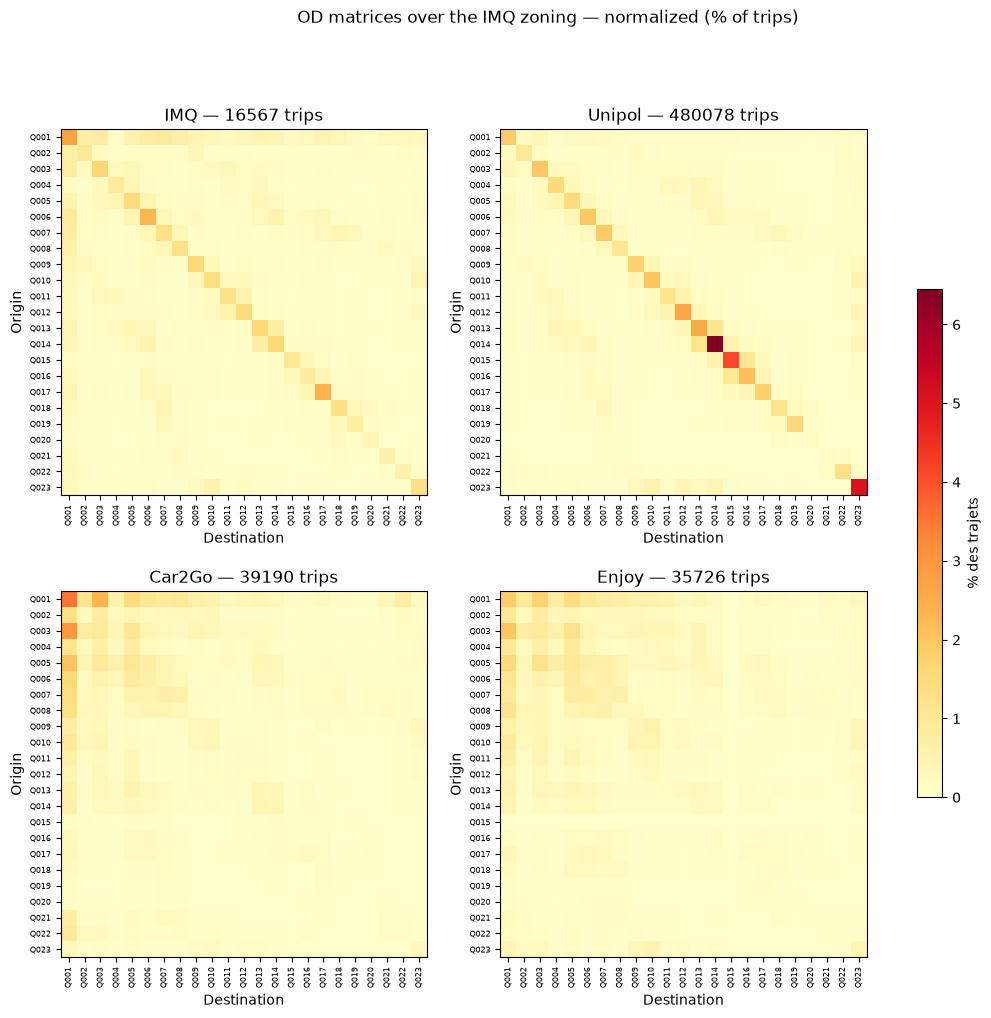

In [58]:
probs = {"IMQ": P_imq, "Unipol": P_uni, "Car2Go": P_c2g, "Enjoy": P_enjoy}
vmax = max(100 * P.to_numpy().max() for P in probs.values())

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (name, OD) in zip(axes.flat, mats.items()):
    im = ax.imshow(100 * probs[name].to_numpy(), cmap="YlOrRd", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(codes)))
    ax.set_xticklabels(codes, rotation=90, fontsize=6)
    ax.set_yticks(range(len(codes)))
    ax.set_yticklabels(codes, fontsize=6)
    ax.set_title(f"{name} — {int(OD.to_numpy().sum())} trips")
    ax.set_xlabel("Destination")
    ax.set_ylabel("Origin")
fig.colorbar(im, ax=axes, shrink=0.6, label="% des trajets")
fig.suptitle("OD matrices over the IMQ zoning — normalized (% of trips)")
plt.show()

### Explanation of why there is no point in Q15 for Enjoy 

In [59]:
pts = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(trips_enjoy_z.origin_lon, trips_enjoy_z.origin_lat),
    crs="EPSG:4326")
cnt = pts.sjoin(zones_imq[["zone_code", "geometry"]],
                predicate="within")["zone_code"].value_counts()
print(cnt.reindex(codes, fill_value=0).sort_values().head(8))

zone_code
Q015      2
Q019    261
Q020    316
Q022    453
Q021    481
Q016    674
Q018    729
Q017    889
Name: count, dtype: int64


In [60]:
m = zones_imq.explore(tiles="OpenStreetMap",
                      style_kwds={"fillOpacity": 0.05, "weight": 1})
zones_imq[zones_imq.zone_code == "Q015"].explore(
    m=m, color="red", style_kwds={"fillOpacity": 0.4, "weight": 3},
    tooltip=["zone_code", "zone_name", "area_km2"])
pts.sample(3000).explore(m=m, color="blue", marker_type="circle_marker",
                         marker_kwds={"radius": 2, "fill": True})
m   # la zone rouge contient-elle le moindre point bleu ?

### Comparison between Car2Go Enjoy and IMQ by gender and age.

In [61]:

GENDER_LABEL = {1: "Men", 2: "Women"}     

rows = []
for (sex, age), grp in dfIMQ.groupby(["GENDER", "AGE"]):
    OD_g = od_matrix(grp, codes)                              
    n = int(OD_g.to_numpy().sum())
    P_g = OD_g.to_numpy() / n                                
    rows.append({
        "sex":    GENDER_LABEL.get(sex, sex),
        "age":    age,
        "trips":  n,
        "JS_Car2Go": round(js_divergence(P_g, P_c2g.to_numpy()), 4),
        "JS_Enjoy":  round(js_divergence(P_g, P_enjoy.to_numpy()), 4),
    })

js_age_sex = pd.DataFrame(rows).sort_values(["sex", "age"]).reset_index(drop=True)
js_age_sex["closest_source"] = np.where(
    js_age_sex["JS_Car2Go"] <= js_age_sex["JS_Enjoy"], "Car2Go", "Enjoy")

print("Jensen-Shannon distance (0 = identical) by age × sex group")
display(js_age_sex)

# Summary: which group is most similar to each source?
for src in ["Car2Go", "Enjoy"]:
    best = js_age_sex.sort_values(f"JS_{src}").iloc[0]
    print(f"Closest profile to {src}: {best.sex}, age {best.age} "
          f"(JS = {best[f'JS_{src}']:.4f}, {int(best.trips)} trips)")

Jensen-Shannon distance (0 = identical) by age × sex group


,sex,age,trips,JS_Car2Go,JS_Enjoy,closest_source
0,Men,1,710,0.5463,0.5608,Car2Go
1,Men,2,3691,0.3678,0.3782,Car2Go
2,Men,3,1842,0.4354,0.4506,Car2Go
3,Men,4,1666,0.5071,0.5221,Car2Go
4,Women,1,660,0.5042,0.5192,Car2Go
5,Women,2,4188,0.4038,0.4230,Car2Go
6,Women,3,1983,0.4557,0.4756,Car2Go
7,Women,4,1827,0.5232,0.5398,Car2Go


Closest profile to Car2Go: Men, age 2 (JS = 0.3678, 3691 trips)
Closest profile to Enjoy: Men, age 2 (JS = 0.3782, 3691 trips)


### Comparison of the 3 OD Matrices 

Jensen-Shannon distance between sources (0 = identical distributions)


,IMQ,Unipol,Car2Go,Enjoy
IMQ,0.0000,0.3086,0.3765,0.3958
Unipol,0.3086,0.0000,0.5443,0.5554
Car2Go,0.3765,0.5443,0.0000,0.2073
Enjoy,0.3958,0.5554,0.2073,0.0000


,pair,JS,closest
0,Car2Go ↔ Enjoy,0.2073,True
1,IMQ ↔ Unipol,0.3086,False
2,IMQ ↔ Car2Go,0.3765,False
3,IMQ ↔ Enjoy,0.3958,False
4,Unipol ↔ Car2Go,0.5443,False
5,Unipol ↔ Enjoy,0.5554,False


Closest pair  : Car2Go ↔ Enjoy (JS = 0.2073)
Farthest pair : Unipol ↔ Enjoy (JS = 0.5554)


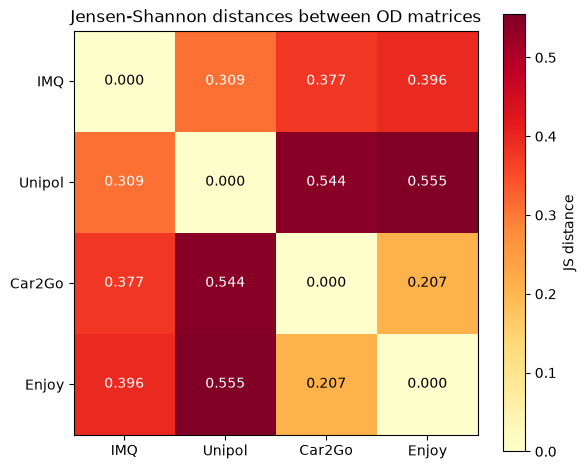

In [62]:
prob = {"IMQ": P_imq, "Unipol": P_uni, "Car2Go": P_c2g, "Enjoy": P_enjoy}
# Variant: compare against the IMQ reweighted by the sampling weights
# prob["IMQ"] = OD_w.to_numpy() / OD_w.to_numpy().sum()

# 4x4 matrix of pairwise JS distances
js_tab = pd.DataFrame(0.0, index=prob.keys(), columns=prob.keys())
for a, b in combinations(prob.keys(), 2):
    v = js_divergence(prob[a].to_numpy(), prob[b].to_numpy())
    js_tab.loc[a, b] = js_tab.loc[b, a] = round(v, 4)

print("Jensen-Shannon distance between sources (0 = identical distributions)")
display(js_tab)

# Ranking of pairs: from closest to farthest
pairs = pd.DataFrame(
    [{"pair": f"{a} ↔ {b}",
      "JS": js_divergence(prob[a].to_numpy(), prob[b].to_numpy())}
     for a, b in combinations(prob.keys(), 2)]
).sort_values("JS").reset_index(drop=True)
pairs["closest"] = pairs["JS"] == pairs["JS"].min()
display(pairs.round(4))

print(f"Closest pair  : {pairs.iloc[0].pair} (JS = {pairs.iloc[0].JS:.4f})")
print(f"Farthest pair : {pairs.iloc[-1].pair} (JS = {pairs.iloc[-1].JS:.4f})")

# Summary heatmap
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(js_tab.to_numpy(), cmap="YlOrRd")
ax.set_xticks(range(len(js_tab))); ax.set_xticklabels(js_tab.columns)
ax.set_yticks(range(len(js_tab))); ax.set_yticklabels(js_tab.index)
for i in range(len(js_tab)):
    for j in range(len(js_tab)):
        ax.text(j, i, f"{js_tab.iloc[i, j]:.3f}", ha="center", va="center",
                color="white" if js_tab.iloc[i, j] > js_tab.to_numpy().max()/2 else "black")
fig.colorbar(im, label="JS distance")
ax.set_title("Jensen-Shannon distances between OD matrices")
plt.tight_layout(); plt.show()

## Question 4

First idea to improve the zoning system is to adapt it to the data, their distribution and number

In [63]:
def prepare_od_data(df, epsg=32632):
    data = df.copy()
    # longitude and latitude
    data["origin_lon"] = data["init_loc"].apply(lambda x: x["coordinates"][0])
    data["origin_lat"] = data["init_loc"].apply(lambda x: x["coordinates"][1])

    data["destination_lon"] = data["final_loc"].apply(lambda x: x["coordinates"][0])
    data["destination_lat"] = data["final_loc"].apply(lambda x: x["coordinates"][1])

    # Project coordinates into a metric CRS
    origins = gpd.GeoSeries(gpd.points_from_xy(data["origin_lon"], data["origin_lat"]),crs="EPSG:4326").to_crs(epsg=epsg)

    destinations = gpd.GeoSeries(gpd.points_from_xy(data["destination_lon"], data["destination_lat"]),crs="EPSG:4326").to_crs(epsg=epsg)

    data["start_x"] = origins.x
    data["start_y"] = origins.y
    data["end_x"] = destinations.x
    data["end_y"] = destinations.y

    data["init_date"] = pd.to_datetime(data["init_date"])

    return data

In [64]:
def make_od_grid(data, h=1000):  #from ex2
    # Fixed grid origin
    x0 = np.floor(min(data["start_x"].min(), data["end_x"].min()) / h) * h
    y0 = np.floor(min(data["start_y"].min(), data["end_y"].min()) / h) * h
    x_max = max(data["start_x"].max(), data["end_x"].max())
    y_max = max(data["start_y"].max(), data["end_y"].max())

    n_cols = int(np.floor((x_max - x0) / h)) + 1
    n_rows = int(np.floor((y_max - y0) / h)) + 1

    polygons = []
    for row in range(n_rows):
        for col in range(n_cols):
            x = x0 + col * h
            y = y0 + row * h
            polygons.append(box(x, y, x + h, y + h))

    zones = gpd.GeoDataFrame({"zone_id": range(n_rows * n_cols)},
                             geometry=polygons,crs="EPSG:32632")

    # Assign origins and destinations
    trips = data.copy()
    
    # Remove missing or infinite coordinates
    cols = ["start_x", "start_y", "end_x", "end_y"]
    trips = trips.replace([np.inf, -np.inf], np.nan)
    trips = trips.dropna(subset=cols).copy()

    origin_col = np.floor((trips["start_x"] - x0) / h).astype(int)
    origin_row = np.floor((trips["start_y"] - y0) / h).astype(int)
    destination_col = np.floor((trips["end_x"] - x0) / h).astype(int)
    destination_row = np.floor((trips["end_y"] - y0) / h).astype(int)

    trips["origin"] = origin_row * n_cols + origin_col
    trips["destination"] = destination_row * n_cols + destination_col

    return trips, zones

In [65]:
def compute_marginalproba(trips,zones):
    # value count compte les occurences dans chaque zone des origines et départs
    # reindex(zones.index, fill_value=0) : il garantit que les zones vides soient conservées et recoivent un 0
    zones["origin_count"] = trips["origin"].value_counts().reindex(zones.index, fill_value=0)
    zones["destination_count"] = trips["destination"].value_counts().reindex(zones.index, fill_value=0)
    zones["pO"] = zones["origin_count"] / N_train # proba marginale
    zones["pD"] = zones["destination_count"] / N_train
    
    print("Sum of pO:", zones["pO"].sum())
    print("Sum of pD:", zones["pD"].sum())
    display(zones[["zone_id", "origin_count", "destination_count", "pO", "pD"]].head())

In [66]:
def compute_ODmat(trips, zones):
    OD_counts = pd.crosstab(trips["origin"], trips["destination"])
    OD_counts = OD_counts.reindex(index=zones.index, columns=zones.index, fill_value=0)
    OD_counts.index.name = "origin"
    OD_counts.columns.name = "dest"
    
    OD_probability = OD_counts / N_train
    
    print("OD matrix shape:", OD_counts.shape)
    print("Total observed trips:", OD_counts.to_numpy().sum())
    print("Total joint probability:", OD_probability.to_numpy().sum())
    print("Symmetric count matrix:", OD_counts.equals(OD_counts.T))
    display(OD_probability.iloc[:10, :10])

In [67]:
def compute_od_by_period(trips, zones):
    trips = trips.copy()
    trips["init_date"] = pd.to_datetime(trips["init_date"])

    trips["day_type"] = np.where(
        trips["init_date"].dt.dayofweek < 5,
        "Weekdays",
        "Weekends"
    )

    trips["time_type"] = np.where(
        (trips["init_date"].dt.hour >= 6) &
        (trips["init_date"].dt.hour < 22),
        "Daytime",
        "Night-time"
    )

    od_results = {}

    categories = {
        "Weekdays": trips[trips["day_type"] == "Weekdays"],
        "Weekends": trips[trips["day_type"] == "Weekends"],
        "Daytime": trips[trips["time_type"] == "Daytime"],
        "Night-time": trips[trips["time_type"] == "Night-time"]
    }

    for name, group in categories.items():
        if group.empty:
            continue

        # OD count matrix
        OD_counts = pd.crosstab(
            group["origin"],
            group["destination"]
        ).reindex(
            index=zones.index,
            columns=zones.index,
            fill_value=0
        )

        OD_counts.index.name = "origin"
        OD_counts.columns.name = "dest"

        # Joint probability matrix
        N = len(group)
        OD_probability = OD_counts / N

        od_results[name] = {
            "counts": OD_counts,
            "probability": OD_probability,
            "n_trips": N
        }

        print(
            f"{name}: {N} trips | "
            f"Probability sum: {OD_probability.to_numpy().sum():.4f}"
        )

    return od_results

In [68]:
def plot_od_periods(OD_results, zones):

    zones_maps = {}

    for name, result in OD_results.items():

        OD = result["probability"]

        # Origin and destination probabilities
        pO = OD.sum(axis=1)
        pD = OD.sum(axis=0)

        gdf = zones.copy()

        gdf["pO"] = pO.reindex(zones.index).values
        gdf["pD"] = pD.reindex(zones.index).values

        gdf["origin_count"] = result["counts"].sum(axis=1).values
        gdf["destination_count"] = result["counts"].sum(axis=0).values

        zones_maps[name] = gdf

    # Common scales
    vmax = max(
        max(gdf["pO"].max(), gdf["pD"].max())
        for gdf in zones_maps.values()
    )

    # Create maps
    outputs = []

    for name, gdf in zones_maps.items():

        out = widgets.Output(
            layout=widgets.Layout(width="50%")
        )

        with out:

            print(name)

            m = gdf.explore(
                column="pO",
                cmap=linear.YlOrRd_09.scale(0, vmax),
                tiles="OpenStreetMap",
                tooltip=[
                    "zone_id",
                    "origin_count",
                    "destination_count",
                    "pO",
                    "pD"
                ],
                style_kwds={
                    "fillOpacity": 0.5,
                    "weight": 0.5
                },
                legend=True
            )

            display(m)

        outputs.append(out)

    display(
        widgets.VBox([
            widgets.HBox(outputs[:2]),
            widgets.HBox(outputs[2:])
        ])
    )

    return zones_maps

In [69]:
df_Car2Go=load_wtime(db,pb_coll)
trips_car2Go = prepare_od_data(df_Car2Go)
tripsC2G,zonesC2G=make_od_grid(trips_car2Go)
trips_car2Go = prepare_od_data(df_Car2Go)
tripsC2G,zonesC2G=make_od_grid(trips_car2Go)

In [70]:
N_train=len(tripsC2G)
compute_ODmat(tripsC2G, zonesC2G)

OD matrix shape: (120, 120)
Total observed trips: 39190
Total joint probability: 1.0
Symmetric count matrix: False


dest,0,1,2,3,4,5,6,7,8,9
dest,,,,,,,,,,
0,0.000000,0.000000,0.000026,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,0.000102,0.000000,0.000230,0.000026,0.000026,0.0,0.0,0.0,0.0,0.0
2,0.000000,0.000102,0.000026,0.000026,0.000077,0.0,0.0,0.0,0.0,0.0
3,0.000026,0.000230,0.000051,0.000051,0.000128,0.0,0.0,0.0,0.0,0.0
4,0.000026,0.000026,0.000281,0.000077,0.000051,0.0,0.0,0.0,0.0,0.0
5,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
6,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
7,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
8,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


In [71]:
compute_marginalproba(tripsC2G, zonesC2G)

Sum of pO: 1.0
Sum of pD: 1.0


,zone_id,origin_count,destination_count,pO,pD
dest,,,,,
0,0,11,24,0.000281,0.000612
1,1,125,160,0.003190,0.004083
2,2,112,147,0.002858,0.003751
3,3,150,95,0.003828,0.002424
4,4,322,198,0.008216,0.005052


In [72]:
od_by_period=compute_od_by_period(tripsC2G, zonesC2G)

OD_weekdays = od_by_period["Weekdays"]["probability"]
OD_weekends = od_by_period["Weekends"]["probability"]

OD_daytime = od_by_period["Daytime"]["probability"]
OD_night = od_by_period["Night-time"]["probability"]

Weekdays: 29186 trips | Probability sum: 1.0000
Weekends: 10004 trips | Probability sum: 1.0000
Daytime: 28466 trips | Probability sum: 1.0000
Night-time: 10724 trips | Probability sum: 1.0000


In [73]:
zones_maps = plot_od_periods(od_by_period, zonesC2G)

#### compare side length

In [74]:
side_lengths = sorted(set(list(range(300, 3001, 300)) + [1000]))
results = []

for h in side_lengths:
    trips, zones = make_od_grid(tripsC2G, h)
    K = len(zones)
    active_zones = pd.concat([trips["origin"], trips["destination"]]).nunique()
    observed_pairs = len(trips[["origin", "destination"]].drop_duplicates())
    intrazonal = (trips["origin"] == trips["destination"]).sum()

    results.append({"side_m": h, "K": K, 
                    "active_training_zones": active_zones,
                    "k^2": K**2,
                    "observed_training_OD": observed_pairs,
                    "mean_trips_per_OD": len(trips) / (K * K),
                    "intrazonal_count": intrazonal,
                    "intrazonal_percent": 100 * intrazonal / len(trips)})

zoning_results = pd.DataFrame(results)
zoning_results.round(4)


,side_m,K,active_training_zones,k^2,observed_training_OD,mean_trips_per_OD,intrazonal_count,intrazonal_percent
0,300,1216,674,1478656,28600,0.0265,0,0.0000
1,600,323,197,104329,12994,0.3756,47,0.1199
2,900,168,100,28224,5407,1.3885,487,1.2427
3,1000,120,84,14400,4291,2.7215,690,1.7607
4,1200,90,62,8100,2581,4.8383,1407,3.5902
5,1500,56,44,3136,1488,12.4968,2332,5.9505
6,1800,49,33,2401,875,16.3224,3642,9.2932
7,2100,42,26,1764,518,22.2166,5104,13.0237
8,2400,25,21,625,374,62.7040,6952,17.7392
9,2700,25,19,625,293,62.7040,7997,20.4057


1000x1000 justification:
- 120 zones K^2 = 120^2 = 14,400 theoritical OD pairs (dim ok for analysis of matrices)
- good cover of displacements : 3 709 distincts OD pairs, against only 203 3,000 m grid. --> good spatial diversity
- not much intrazone displacements: 0,76 % of trips
- trade off between resolution and sparsity

In [75]:
for h in [300, 1000, 3000]:
    trips, zones = make_od_grid(trips, h)
    print("Square side:", h, "m | Number of zones:", len(zones))
    display(zones.explore(tiles="OpenStreetMap", color="blue", tooltip="zone_id",
                          style_kwds={"fillOpacity": 0.03, "weight": 0.7}))

Square side: 300 m | Number of zones: 1216


Square side: 1000 m | Number of zones: 120


Square side: 3000 m | Number of zones: 20
